# Isolation Forest · Pozos y meses anómalos

Cuaderno nuevo e independiente, construido a partir de la fuente del notebook **02_modelos_supervisados** y del boxplot de **01_exploracion_inicial**. No requiere ejecutar otros cuadernos. Ejecutar de arriba hacia abajo.

## Qué vamos a responder
1. **Pozos:** ¿cuáles tienen un perfil inusual durante sus primeros doce meses observados de producción?
2. **Meses:** ¿qué registros mensuales son inusuales en el conjunto de pozos y cuáles coinciden con aumentos de producción?
3. ¿Dónde están esos pozos y cómo se ven los eventos en la distribución de meses anómalos y en los boxplots?

En cada grupo se ajustan **dos Isolation Forest con `contamination='auto'`**: uno recibe una fila por pozo; el otro una fila por pozo-mes. Una etiqueta del pozo no identifica automáticamente sus meses anómalos. Este es un análisis retrospectivo descriptivo del archivo disponible, no un pronóstico ni una prueba fuera de muestra.

**Exclusiones del modelo:** `coordenadax`, `coordenaday`, `iny_agua` y `subclasificacion`. Las coordenadas se conservan exclusivamente para el mapa. `idpozo` y fecha sirven para identificar resultados, no como predictores. Las categorías `tipoextraccion`, `tipoestado`, `tipopozo`, `areayacimiento` y `clasificacion` se incorporan con `pd.get_dummies`.

**Cómo leer una anomalía:** significa perfil estadísticamente inusual, no necesariamente error o problema operativo. Un aumento de agua no implica una mejora. `auto` usa el umbral del algoritmo; no fija ni estima un porcentaje verdadero de anomalías.

**Dos poblaciones separadas, cuatro modelos independientes:**
- Bloque principal: La Amarga Chica y Loma Campana (pozos petrolíferos). El Orejano queda excluido antes de construir variables y entrenar.
- Bloque final: solo El Orejano (predominantemente gasífero), con un modelo de primer año y otro mensual propios.

Los scores expresan rareza dentro de cada población y no son probabilidades ni una escala de gravedad comparable entre modelos. Se mantienen las mismas reglas de calidad, primer año 0–11, dummies, proporción `tef / dias_del_mes`, 300 árboles, semilla 42 y `contamination='auto'`.


**Filtro previo a los cuatro modelos:** se excluyen los meses con `prod_pet = prod_gas = prod_agua = 0`. Un cero en uno o dos fluidos no elimina el registro. Los faltantes no se reemplazan por cero. La edad calendario y el primer cambio histórico de extracción se calculan antes del filtro para conservar la referencia temporal original.


In [20]:
from pathlib import Path
import hashlib, json, html, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown, FileLink
from sklearn.ensemble import IsolationForest
import sklearn

# Colab incluye estas bibliotecas; si faltan, instalar desde PyPI oficial.
try:
    import seaborn as sns
    import folium
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'seaborn', 'folium'])
    import seaborn as sns
    import folium

URL_CSV = 'https://github.com/molijoaquin-DA/vaca-muerta-produccion/raw/refs/heads/main/data/processed/produccion_limpia_filtrada.csv'
FUENTE = URL_CSV
SEMILLA = 42
CONTAMINACION = 'auto'
N_ARBOLES = 300
PRIMER_ANIO = range(0, 12)  # Edad cero = primer mes; doce observaciones, no trece.
FECHA_CORTE = None  # None = todo el archivo. Puede indicarse '2026-09-01'.
RAIZ_SALIDA = Path('resultados_isolation_forest_sin_ceros')
SALIDA = RAIZ_SALIDA / 'petroliferos'
SALIDA.mkdir(parents=True, exist_ok=True)
FLUIDOS = {'Petróleo':'prod_pet_dia', 'Gas':'prod_gas_dia', 'Agua':'prod_agua_dia'}
UNIDADES = {'Petróleo':'m³/día efectivo', 'Gas':'miles de m³/día efectivo', 'Agua':'m³/día efectivo'}
PROHIBIDAS = {'coordenadax','coordenaday','iny_agua','subclasificacion','subclasificación'}
CATEGORICAS = ['tipoextraccion','tipoestado','tipopozo','areayacimiento','clasificacion']

def codificar_categorias(datos):
    categorias = datos[CATEGORICAS].astype('string').apply(lambda s: s.str.strip().replace('', pd.NA).fillna('Sin dato'))
    return pd.get_dummies(categorias, columns=CATEGORICAS, prefix_sep='=', drop_first=False, dtype=float)

print('scikit-learn:', sklearn.__version__, '| contamination:', CONTAMINACION)

scikit-learn: 1.6.1 | contamination: auto


## 1. Datos procesados y proporción de tiempo operativo

`fraccion_tiempo_operativo = tef / dias_del_mes`. En este dataset `tef` representa tiempo efectivo y puede tener decimales. Una proporción de 1 equivale al mes completo; 0,5 al 50 % del tiempo y 0 a ninguna actividad efectiva. Esto permite comparar meses de distinta duración. No identifica la causa de una parada.

Se parte del CSV procesado por `01_exploracion_inicial`. Allí se revisaron identificadores y faltantes (celdas 8, 14, 26 y 30), tipos de datos (14–19), duplicados pozo-mes (51) y cambios de tipo de pozo (72). No se repiten esas verificaciones.

Aquí se conservan las condiciones adicionales necesarias para modelar: `0 ≤ tef ≤ días del mes`, volúmenes no negativos y producción positiva sin tiempo efectivo. Los registros incompatibles se exportan y no reciben una etiqueta de anomalía del modelo.

El exploratorio divide los volúmenes por `tef`, pero cuando `tef=0` conserva el volumen como si fuera tasa. Para el modelo, un volumen positivo con `tef=0` queda no evaluable. Los meses con los tres volúmenes iguales a cero se conservan temporalmente para calcular la edad y el historial de extracción; luego se excluyen antes de construir las variables y ajustar los modelos, cualquiera sea su `tef`. Conservamos las tasas originales para reproducir exactamente la población y los valores de los boxplots de referencia.

Este bloque conserva La Amarga Chica y Loma Campana. Se mantiene la comprobación de que los grupos de entrenamiento no compartan pozos, porque corresponde a la separación realizada en este notebook.


In [21]:
#Carga del CSV y eleccion de columnas
df = pd.read_csv(FUENTE, encoding='utf-8-sig', low_memory=False)
df['fecha'] = pd.to_datetime(dict(year=df.anio, month=df.mes, day=1))
df = df.sort_values(['idpozo','fecha']).reset_index(drop=True)
df['fila_id'] = df.index
df['dias_del_mes'] = df.fecha.dt.days_in_month
df['fraccion_tiempo_operativo'] = df.tef / df.dias_del_mes
vols = ['prod_pet','prod_gas','prod_agua']

# Condiciones adicionales para calcular tasas y entrenar los modelos
df['calidad_tef_ok'] = df.tef.between(0,df.dias_del_mes)
df['calidad_volumen_ok'] = df[vols].ge(0).all(axis=1)
df['volumen_sin_tiempo'] = df.tef.eq(0) & df[vols].gt(0).any(axis=1)
df['registro_valido'] = df.calidad_tef_ok & df.calidad_volumen_ok & ~df.volumen_sin_tiempo
TASAS = []
for original,vol in zip(FLUIDOS.values(),vols):
    c = original+'_modelo'
    df[c] = df[vol]/df.tef.where(df.tef>0)
    df.loc[df.tef.eq(0) & df[vol].eq(0),c] = 0
    df.loc[~df.registro_valido,c] = np.nan
    TASAS.append(c)

# Separar registros antes de cualquier construcción de perfiles o ajuste.
datos_preparados = df.copy()
mask_orejano = datos_preparados['areayacimiento'].eq('EL OREJANO')
ids_orejano = set(datos_preparados.loc[mask_orejano, 'idpozo'])
ids_petroliferos = set(datos_preparados.loc[~mask_orejano, 'idpozo'])


# Pozos de yacimiento que no es El Orejano
df = datos_preparados.loc[~mask_orejano].copy().reset_index(drop=True)
print('BLOQUE PETROLÍFEROS: La Amarga Chica y Loma Campana; El Orejano excluido.')
df.loc[~df.registro_valido].to_csv(SALIDA/'registros_no_evaluables.csv',index=False)
print('Filas:',len(df),'| Pozos:',df.idpozo.nunique(),'| Último mes:',df.fecha.max().date())
print('Registros no evaluables:',int((~df.registro_valido).sum()))
display(df[['idpozo','fecha','tef','dias_del_mes','fraccion_tiempo_operativo','registro_valido']].head())

BLOQUE PETROLÍFEROS: La Amarga Chica y Loma Campana; El Orejano excluido.
Filas: 25950 | Pozos: 449 | Último mes: 2026-09-01
Registros no evaluables: 2


,idpozo,fecha,tef,dias_del_mes,fraccion_tiempo_operativo,registro_valido
0,145735,2013-10-01,10.00,31,0.322581,True
1,145735,2013-11-01,30.00,30,1.000000,True
2,145735,2013-12-01,31.00,31,1.000000,True
3,145735,2014-01-01,31.00,31,1.000000,True
4,145735,2014-02-01,26.69,28,0.953214,True


## 2. Edad del pozo y primer cambio de método de extracción

Este bloque utiliza `edad_pozo_meses` del CSV procesado. La fecha inicial observada se obtiene solo para ubicar la franja del primer año en el gráfico histórico; no se recalcula la edad en este bloque.

`edad_primer_cambio_metodo` indica la edad en la **primera observación de un método distinto al anterior**, considerando todo el historial disponible. Un valor faltante significa “no se observó cambio”, no “jamás cambió”. Si faltan meses entre métodos, la fecha exacta del cambio no se conoce: se informa el intervalo entre observaciones.

Guardamos esa columna completa como contexto. En el modelo del primer año solo se incorpora el cambio observado dentro de los meses 0–11; usar un cambio del año cinco describiría información exterior a la ventana solicitada.

In [22]:
# Fecha de referencia para el gráfico histórico; no recalcula la edad del CSV.
inicio = df.loc[df.tipoestado.eq('Extracción Efectiva')].groupby('idpozo').fecha.min()
df['fecha_inicio_observada'] = df.idpozo.map(inicio)
metodos = df[['idpozo','fecha','edad_pozo_meses','tipoextraccion']].copy()
metodos['metodo_anterior'] = metodos.groupby('idpozo').tipoextraccion.shift()
metodos['fecha_metodo_anterior'] = metodos.groupby('idpozo').fecha.shift()
metodos['cambio_metodo'] = metodos.metodo_anterior.notna() & metodos.tipoextraccion.ne(metodos.metodo_anterior)
cambios = metodos.loc[metodos.cambio_metodo].copy()
cambios['intervalo_cambio_meses'] = ((cambios.fecha.dt.year-cambios.fecha_metodo_anterior.dt.year)*12
                                   + cambios.fecha.dt.month-cambios.fecha_metodo_anterior.dt.month)
primer_cambio = cambios.drop_duplicates('idpozo').rename(columns={
    'edad_pozo_meses':'edad_primer_cambio_metodo','fecha':'fecha_primer_cambio_metodo',
    'tipoextraccion':'primer_metodo_nuevo'})
campos_cambio = ['idpozo','edad_primer_cambio_metodo','fecha_primer_cambio_metodo',
                 'fecha_metodo_anterior','intervalo_cambio_meses','metodo_anterior','primer_metodo_nuevo']
df = df.merge(primer_cambio[campos_cambio],on='idpozo',how='left',validate='many_to_one')
primer_cambio[campos_cambio].to_csv(SALIDA/'primer_cambio_metodo.csv',index=False)
df['en_primer_anio'] = df.edad_pozo_meses.isin(PRIMER_ANIO)
display(df[['idpozo','edad_primer_cambio_metodo','intervalo_cambio_meses']].drop_duplicates().head(10))

# Excluir meses sin producción en los tres fluidos ANTES de crear perfiles y modelos.
# La edad y el primer cambio de método se calcularon con el historial completo.
sin_produccion = df[['prod_pet', 'prod_gas', 'prod_agua']].eq(0).all(axis=1)
meses_excluidos_cero = df.loc[sin_produccion].copy()
meses_excluidos_cero.to_csv(SALIDA/'meses_excluidos_produccion_cero.csv', index=False)
df = df.loc[~sin_produccion].copy().reset_index(drop=True)
print('Meses excluidos por producción cero en los tres fluidos:', len(meses_excluidos_cero))
print('Registros restantes antes de construir los modelos:', len(df))

,idpozo,edad_primer_cambio_metodo,intervalo_cambio_meses
0,145735,13.0,1.0
122,145739,13.0,1.0
220,145881,5.0,1.0
375,145882,5.0,1.0
523,145883,10.0,1.0
674,145884,12.0,1.0
822,145887,11.0,1.0
977,145888,12.0,1.0
1132,145889,12.0,1.0
1275,145890,NaN,NaN


Meses excluidos por producción cero en los tres fluidos: 2379
Registros restantes antes de construir los modelos: 23571


## 3. Una fila por pozo: describir el primer año

Se incluyen pozos con **los doce meses calendario 0–11 presentes y válidos**. No reemplazamos meses ausentes por cero. Los pozos nuevos o con huecos se reportan como “no evaluables” para este modelo, aunque pueden tener meses evaluables en el modelo mensual.

Por cada tasa y por proporción de tiempo operativo se calculan media, mediana, desviación estándar, mínimo y máximo. También se incluyen la fracción de meses sin actividad efectiva y el cambio de método dentro del año. Estos resúmenes están correlacionados: el resultado depende de esta representación, no es una clasificación universal de pozos.

Este bloque compara únicamente los pozos petrolíferos elegibles de La Amarga Chica y Loma Campana. El Orejano no participa del ajuste ni del cálculo de variables. Las diferencias entre los dos yacimientos todavía pueden influir en la rareza.

Las cinco variables categóricas se convierten a indicadores 0/1 mediante `pd.get_dummies`. En el modelo anual se promedian estos indicadores **solo en los meses 0–11**: por ejemplo, 0,75 en un método indica que se observó en 9 de 12 meses. Una categoría constante conserva su indicador. Las categorías poco frecuentes también pueden influir en las alertas; codificarlas no equivale a entrenar un modelo separado por grupo. [Documentación de get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html).

El requisito de doce meses válidos permanece: si el filtro elimina un mes del primer año, ese pozo no se evalúa en el modelo anual. No se reemplaza el mes excluido por otro posterior ni se redefine el inicio de producción. Sus otros meses pueden seguir siendo evaluables en el modelo mensual.


In [23]:
# Variables descriptivas en el período de ventana
ventana = df.loc[df.en_primer_anio].copy()
cobertura = df.groupby('idpozo').agg(edad_max=('edad_pozo_meses','max'))
cuentas = ventana.groupby('idpozo').agg(meses_presentes=('fecha','size'),meses_validos=('registro_valido','sum'),edades_distintas=('edad_pozo_meses','nunique'))
cobertura = cobertura.join(cuentas).fillna({'meses_presentes':0,'meses_validos':0,'edades_distintas':0})
cobertura['evaluable_pozo'] = cobertura.meses_presentes.eq(12) & cobertura.meses_validos.eq(12) & cobertura.edades_distintas.eq(12)
cobertura['motivo'] = np.select([cobertura.evaluable_pozo,cobertura.edad_max.isna(),cobertura.edad_max.lt(11),cobertura.meses_presentes.lt(12)],
    ['evaluable','sin inicio productivo observado','primer año aún no completo','faltan meses del primer año'],default='registros inválidos en el primer año')
elegibles = cobertura.index[cobertura.evaluable_pozo]
v = ventana.loc[ventana.idpozo.isin(elegibles)].copy()
DESCRIBIR = TASAS + ['fraccion_tiempo_operativo']
perfiles = v.groupby('idpozo')[DESCRIBIR].agg(['mean','median','std','min','max'])
perfiles.columns = ['__'.join(c) for c in perfiles.columns]
perfiles['fraccion_meses_tef_cero'] = v.groupby('idpozo').tef.apply(lambda s:float(s.eq(0).mean()))
# Solo transiciones observadas en la ventana, aunque el primer cambio histórico fuera anterior.
cambios_12 = cambios.loc[cambios.edad_pozo_meses.isin(PRIMER_ANIO)].groupby('idpozo').edad_pozo_meses.min()
perfiles['hubo_cambio_metodo_12m'] = perfiles.index.isin(cambios_12.index).astype(int)
perfiles['edad_cambio_metodo_12m'] = perfiles.index.map(cambios_12).fillna(12)
# 12 es un código de ausencia dentro de la ventana, acompañado por la bandera anterior.
dummies_12 = codificar_categorias(v)
proporciones_categoricas = dummies_12.groupby(v.idpozo).mean().add_prefix('proporcion_12m_')
perfiles = perfiles.join(proporciones_categoricas, validate='one_to_one')

FEATURES_POZOS = perfiles.columns.tolist()
print('Pozos evaluables:',len(perfiles),'| No evaluables:',int((~cobertura.evaluable_pozo).sum()))
display(cobertura.motivo.value_counts().to_frame('pozos'))
display(perfiles.head())

Pozos evaluables: 384 | No evaluables: 65


,pozos
motivo,
evaluable,384
primer año aún no completo,46
faltan meses del primer año,19


,prod_pet_dia_modelo__mean,prod_pet_dia_modelo__median,prod_pet_dia_modelo__std,prod_pet_dia_modelo__min,prod_pet_dia_modelo__max,prod_gas_dia_modelo__mean,prod_gas_dia_modelo__median,prod_gas_dia_modelo__std,prod_gas_dia_modelo__min,prod_gas_dia_modelo__max,...,fraccion_meses_tef_cero,hubo_cambio_metodo_12m,edad_cambio_metodo_12m,proporcion_12m_tipoextraccion=Bombeo Mecánico,proporcion_12m_tipoextraccion=Surgencia Natural,proporcion_12m_tipoestado=Extracción Efectiva,proporcion_12m_tipopozo=Petrolífero,proporcion_12m_areayacimiento=LA AMARGA CHICA,proporcion_12m_areayacimiento=LOMA CAMPANA,proporcion_12m_clasificacion=EXPLOTACION
idpozo,,,,,,,,,,,,,,,,,,,,,
145735,21.474148,15.943274,19.465192,1.129032,62.735000,1.573130,1.553315,0.558138,0.357097,2.577544,...,0.0,0,12.0,0.000000,1.000000,1.0,1.0,0.0,1.0,1.0
145739,9.573631,5.219285,12.745098,1.580606,46.012607,2.220693,2.047144,0.725867,1.110289,4.075139,...,0.0,0,12.0,0.000000,1.000000,1.0,1.0,0.0,1.0,1.0
145881,10.345924,9.275937,4.108618,2.755752,16.777409,1.296379,1.392083,0.690318,0.262655,2.196092,...,0.0,1,0.0,0.583333,0.416667,1.0,1.0,0.0,1.0,1.0
145882,9.677864,8.638965,6.054112,3.026129,19.659811,1.147512,1.215316,0.658225,0.273333,2.359897,...,0.0,1,0.0,0.583333,0.416667,1.0,1.0,0.0,1.0,1.0
145883,13.310995,8.695184,11.131872,1.447154,36.642126,1.390458,1.002505,1.125167,0.386709,4.726973,...,0.0,1,0.0,0.166667,0.833333,1.0,1.0,0.0,1.0,1.0


## 3.1. Isolation Forest de pozos y gráfico de barras

Isolation Forest intenta aislar cada fila mediante divisiones aleatorias. Perfiles aislados con facilidad reciben mayor rareza. `predict=-1` marca anómalo y `predict=1` no marcado. Mostramos `-score_samples`: **más alto = más raro**, pero no es una probabilidad.

Con `contamination='auto'`, el corte en `decision_function` es cero (y `offset_` es −0,5 en esta implementación). No se obliga a que un porcentaje fijo salga anómalo. Aplicamos `log1p` a los descriptores no negativos de producción para moderar las colas; la proporción operativa, las categorías codificadas y las variables de cambio de método permanecen en su escala.

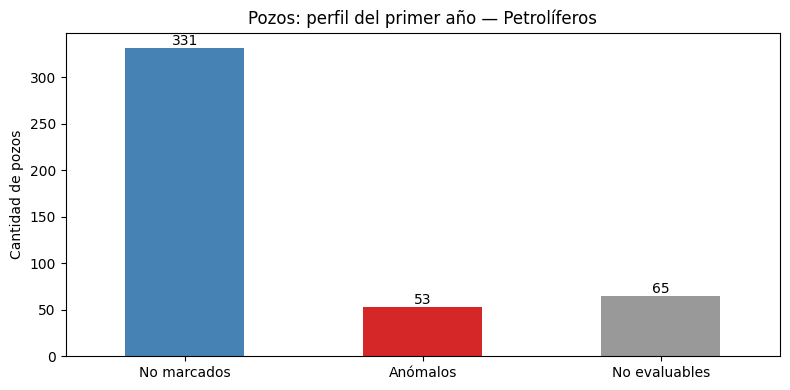

Umbral automático (score): 0.5


,score_pozo,anomalo_pozo,tipopozo,areayacimiento,edad_primer_cambio_metodo
idpozo,,,,,
146222,0.684652,True,Petrolífero,LOMA CAMPANA,4.0
146223,0.646847,True,Petrolífero,LOMA CAMPANA,7.0
145887,0.645581,True,Petrolífero,LOMA CAMPANA,11.0
155042,0.638523,True,Petrolífero,LOMA CAMPANA,3.0
146051,0.636776,True,Petrolífero,LOMA CAMPANA,10.0
155040,0.619965,True,Petrolífero,LOMA CAMPANA,3.0
145881,0.610206,True,Petrolífero,LOMA CAMPANA,5.0
145882,0.602862,True,Petrolífero,LOMA CAMPANA,5.0
155430,0.599349,True,Petrolífero,LOMA CAMPANA,2.0


anomalo_pozo,False,True
tipopozo,,
Petrolífero,331,53


In [24]:
X_pozos = perfiles.copy()
cols_log = [c for c in FEATURES_POZOS if any(c.startswith(t+'__') for t in TASAS)]
X_pozos[cols_log] = np.log1p(X_pozos[cols_log])
modelo_pozos = IsolationForest(n_estimators=N_ARBOLES, contamination=CONTAMINACION,
                               random_state=SEMILLA,n_jobs=-1)
modelo_pozos.fit(X_pozos)
resultado_pozos = perfiles.copy()
resultado_pozos['anomalo_pozo'] = modelo_pozos.predict(X_pozos)==-1
resultado_pozos['score_pozo'] = -modelo_pozos.score_samples(X_pozos)
# Metadatos del pozo: último registro disponible, solo para interpretar y mapear.
meta = df.sort_values('fecha').drop_duplicates('idpozo',keep='last').set_index('idpozo')
meta_cols = ['areayacimiento','tipopozo','coordenadax','coordenaday','edad_primer_cambio_metodo','intervalo_cambio_meses']
resultado_pozos = resultado_pozos.join(meta[meta_cols]).sort_values('score_pozo',ascending=False)
resultado_pozos.to_csv(SALIDA/'resultado_pozos.csv')
conteo = pd.Series({'No marcados':int((~resultado_pozos.anomalo_pozo).sum()),
                   'Anómalos':int(resultado_pozos.anomalo_pozo.sum()),
                   'No evaluables':int((~cobertura.evaluable_pozo).sum())})
ax=conteo.plot.bar(color=['#4682b4','#d62728','#999999'],figsize=(8,4),rot=0)
for i,n in enumerate(conteo):ax.text(i,n,str(n),ha='center',va='bottom')
ax.set(title='Pozos: perfil del primer año — Petrolíferos',ylabel='Cantidad de pozos');plt.tight_layout();plt.show()
print('Umbral automático (score):',-modelo_pozos.offset_)
display(resultado_pozos[['score_pozo','anomalo_pozo','tipopozo','areayacimiento','edad_primer_cambio_metodo']].head(20))
display(pd.crosstab(resultado_pozos.tipopozo,resultado_pozos.anomalo_pozo))

## 3.2. Mapa de pozos

**Forma = yacimiento; color = resultado del modelo de primer año.** Rojo: anómalo; azul: no marcado; gris: no evaluable. Se incluye un mapa estático con formas y un mapa navegable con leyenda y ventanas de información.

`coordenadax` es longitud y `coordenaday` latitud, como en el mapa de la exploración inicial. No intervienen en el ajuste. Se usa la última ubicación completa por pozo; se exportan casos con ubicaciones múltiples y se informa cuántos no pueden ubicarse. Los puntos superpuestos pueden corresponder a pozos distintos.

Mapa navegable: fondo World Street Map de Esri.

Pozos sin ubicación válida: 0


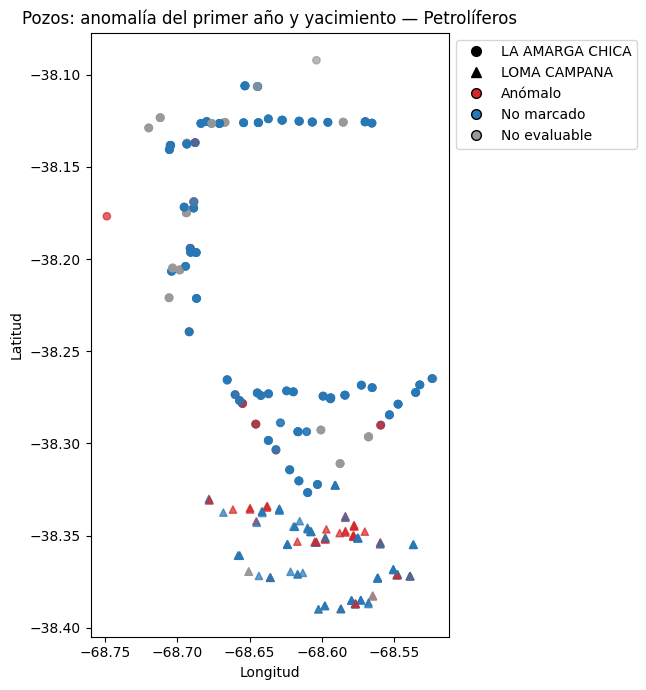

In [25]:
ubicaciones = df.dropna(subset=['coordenadax','coordenaday']).sort_values('fecha')
valid_geo = ubicaciones.coordenadax.between(-180,180) & ubicaciones.coordenaday.between(-90,90)
ubicaciones = ubicaciones.loc[valid_geo]
variaciones = ubicaciones[['idpozo','coordenadax','coordenaday']].drop_duplicates().groupby('idpozo').size()
variaciones.loc[variaciones>1].to_csv(SALIDA/'pozos_con_varias_ubicaciones.csv',header=['ubicaciones'])
mapa_df = meta[['areayacimiento']].join(ubicaciones.drop_duplicates('idpozo',keep='last').set_index('idpozo')[['coordenadax','coordenaday']])
mapa_df = mapa_df.join(resultado_pozos[['anomalo_pozo','score_pozo']])
mapa_df['estado_modelo'] = np.select([mapa_df.anomalo_pozo.isna(),mapa_df.anomalo_pozo.eq(True)],['No evaluable','Anómalo'],default='No marcado')
print('Pozos sin ubicación válida:',int(mapa_df[['coordenadax','coordenaday']].isna().any(axis=1).sum()))
mapa_df = mapa_df.dropna(subset=['coordenadax','coordenaday']).copy()
areas = sorted(mapa_df.areayacimiento.dropna().unique())
FORMAS = dict(zip(areas,['o','^','s','D','v','P','X']))
COLORES = {'Anómalo':'#d62728','No marcado':'#2878b5','No evaluable':'#999999'}
fig,ax=plt.subplots(figsize=(10,7))
for area,g in mapa_df.groupby('areayacimiento'):
    ax.scatter(g.coordenadax,g.coordenaday,c=g.estado_modelo.map(COLORES),marker=FORMAS.get(area,'o'),s=28,alpha=.7)
leyenda=[Line2D([0],[0],marker=FORMAS.get(a,'o'),color='none',markerfacecolor='black',label=a,markersize=7) for a in areas]
leyenda += [Line2D([0],[0],marker='o',color='none',markerfacecolor=c,label=e,markersize=7) for e,c in COLORES.items()]
ax.legend(handles=leyenda,bbox_to_anchor=(1,1));ax.set(xlabel='Longitud',ylabel='Latitud',title='Pozos: anomalía del primer año y yacimiento — Petrolíferos')
ax.set_aspect(1/np.cos(np.deg2rad(mapa_df.coordenaday.mean())));plt.tight_layout();plt.show()

mapa = folium.Map(location=[mapa_df.coordenaday.mean(),mapa_df.coordenadax.mean()],zoom_start=10,tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}', attr='Esri')
css_formas = {}
for i,area in enumerate(areas):
    css_formas[area] = ['border-radius:50%;','clip-path:polygon(50% 0,0 100%,100% 100%);',''][i%3]
    capa=folium.FeatureGroup(name=area,show=True)
    for pozo,r in mapa_df.loc[mapa_df.areayacimiento.eq(area)].iterrows():
        color=COLORES[r.estado_modelo]
        icono=folium.DivIcon(html=f'<div style="width:12px;height:12px;background:{color};border:1px solid white;{css_formas[area]}"></div>',icon_size=(12,12),icon_anchor=(6,6))
        folium.Marker([r.coordenaday,r.coordenadax],icon=icono,
            popup=f'Pozo {pozo}<br>{html.escape(str(area))}<br>{r.estado_modelo}<br>Score: {r.score_pozo:.3f}').add_to(capa)
    capa.add_to(mapa)
leyenda_html='<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;padding:12px;border:1px solid #777;color:black"><b>Color: primer año</b><br>'
for estado,color in COLORES.items():leyenda_html+=f'<span style="color:{color}">●</span> {estado}<br>'
leyenda_html+='<b>Forma: yacimiento</b><br>'
for area in areas:leyenda_html+=f'<span style="display:inline-block;width:12px;height:12px;background:black;{css_formas[area]}"></span> {html.escape(str(area))}<br>'
mapa.get_root().html.add_child(folium.Element(leyenda_html+'</div>'))
folium.LayerControl().add_to(mapa)
display(mapa)

## 4. Un segundo Isolation Forest para localizar meses anómalos

Se usan los meses válidos con un mes calendario previo válido desde el inicio productivo observado, no solo los pozos marcados en el análisis anterior. Así podemos encontrar un evento aislado en un pozo cuyo promedio anual parece normal.

Entradas: tasas actuales, proporción de tiempo operativo, edad, categorías codificadas con `pd.get_dummies` y cambio logarítmico respecto del mes calendario anterior. Para evaluar cambios se exige un mes calendario anterior válido. Los primeros registros y los meses posteriores a un hueco se conservan como no evaluables en este modelo mensual: no se los marca como anómalos solo por faltar contexto. El modelo de pozos sí incluye el primer mes dentro de su resumen anual.

Es un ajuste retrospectivo sobre todo el período: compara registros pozo-mes del grupo petrolífero, **no exclusivamente pares del mismo mes**. Incluye edad para contextualizar, pero no garantiza controlar completamente la etapa productiva o las diferencias entre yacimientos. Los pozos con más historia aportan más filas.

`anomalo_mes` identifica cualquier combinación inusual. `aumento_anomalo` además exige un incremento de al menos una tasa con mes anterior válido. El score multivariado no demuestra que el aumento sea la causa de la alerta; puede haber caídas simultáneas de otros fluidos. Se identifican por separado las salidas de cero.

Las categorías corresponden al mismo registro mensual. No se utiliza una categoría futura ni el identificador del pozo como predictor.

Los meses sin producción conjunta se eliminan antes de crear las variables mensuales. La comparación sigue exigiendo el **mes calendario anterior**: el mes posterior a uno eliminado queda sin contexto y no se evalúa; no se conectan meses separados por un hueco.


,registros
motivo_no_evaluable_mes,
evaluable,22662
falta mes calendario anterior válido,460
sin mes de vida anterior disponible,447
datos de producción/tef inválidos,2


Meses evaluables: 22662 | Meses anómalos: 3801
Pozos con algún mes anómalo: 436
Meses anómalos con aumento de al menos un fluido: 3024


,idpozo,fecha,edad_pozo_meses,score_mes,aumento_anomalo,reactivacion_en_mes_anomalo
19416,164031,2024-11-01,21.0,0.735130,True,False
21514,165269,2025-02-01,10.0,0.731837,True,False
16349,163071,2025-06-01,39.0,0.731447,True,False
16825,163234,2024-12-01,31.0,0.731039,True,False
16294,163070,2025-06-01,39.0,0.730428,True,False
12547,161948,2025-05-01,54.0,0.726972,True,False
21455,165267,2025-02-01,10.0,0.724937,True,False
16404,163072,2025-06-01,39.0,0.712171,True,False
14165,162404,2025-06-01,48.0,0.710550,True,False
6996,156744,2019-05-01,35.0,0.710506,False,False


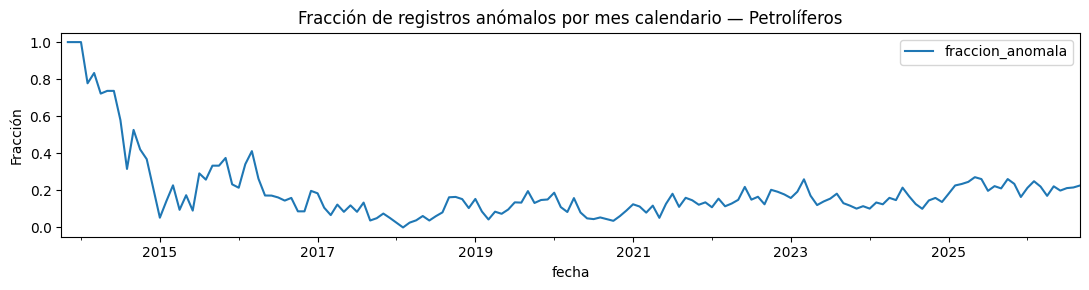

In [26]:
prev = df[['idpozo','fecha','registro_valido']+TASAS].copy()
prev['fecha'] += pd.DateOffset(months=1)
prev = prev.rename(columns={c:c+'_previo' for c in ['registro_valido']+TASAS})
meses = df.merge(prev,on=['idpozo','fecha'],how='left',validate='one_to_one')
meses['sin_mes_previo'] = ~meses.registro_valido_previo.eq(True)
meses['evaluable_mes'] = meses.registro_valido & meses.edad_pozo_meses.ge(1) & ~meses.sin_mes_previo
meses['motivo_no_evaluable_mes'] = np.select([~meses.registro_valido, meses.edad_pozo_meses.isna() | meses.edad_pozo_meses.lt(1), meses.sin_mes_previo], ['datos de producción/tef inválidos','sin mes de vida anterior disponible','falta mes calendario anterior válido'], default='evaluable')
FEATURES_MESES=[]
X_meses=pd.DataFrame(index=meses.index)
for c in TASAS:
    X_meses[c+'_log'] = np.log1p(meses[c])
    cambio=np.log1p(meses[c])-np.log1p(meses[c+'_previo'])
    X_meses[c+'_cambio_log'] = cambio.mask(meses.sin_mes_previo,0)
    meses[c+'_aumenta'] = ~meses.sin_mes_previo & meses[c].gt(meses[c+'_previo'])
    meses[c+'_reactiva'] = ~meses.sin_mes_previo & meses[c+'_previo'].eq(0) & meses[c].gt(0)
X_meses['fraccion_tiempo_operativo'] = meses.fraccion_tiempo_operativo
X_meses['edad_pozo_meses_log'] = np.log1p(meses.edad_pozo_meses.clip(lower=0))
dummies_meses = codificar_categorias(meses)
X_meses = X_meses.join(dummies_meses, validate='one_to_one')
FEATURES_MESES=X_meses.columns.tolist()
validos=meses.evaluable_mes
modelo_meses=IsolationForest(n_estimators=N_ARBOLES,contamination=CONTAMINACION,random_state=SEMILLA,n_jobs=-1)
modelo_meses.fit(X_meses.loc[validos])
meses['anomalo_mes']=pd.Series(pd.NA,index=meses.index,dtype='boolean')
meses.loc[validos,'anomalo_mes']=modelo_meses.predict(X_meses.loc[validos])==-1
meses['score_mes']=np.nan
meses.loc[validos,'score_mes']=-modelo_meses.score_samples(X_meses.loc[validos])
meses['aumento_anomalo']=meses.anomalo_mes.fillna(False) & meses[[c+'_aumenta' for c in TASAS]].any(axis=1)
meses['reactivacion_en_mes_anomalo']=meses.anomalo_mes.fillna(False) & meses[[c+'_reactiva' for c in TASAS]].any(axis=1)
meses.to_csv(SALIDA/'resultado_meses.csv',index=False)
display(meses.motivo_no_evaluable_mes.value_counts().to_frame('registros'))
resumen_mensual=meses.groupby('idpozo').agg(meses_observados=('fecha','size'),meses_evaluables=('evaluable_mes','sum'),
    meses_anomalos=('anomalo_mes','sum'),aumentos_anomalos=('aumento_anomalo','sum'))
resumen_mensual['fraccion_meses_anomalos']=resumen_mensual.meses_anomalos/resumen_mensual.meses_evaluables.replace(0,np.nan)
resumen_mensual.to_csv(SALIDA/'resumen_mensual_por_pozo.csv')
print('Meses evaluables:',int(validos.sum()),'| Meses anómalos:',int(meses.anomalo_mes.sum()))
print('Pozos con algún mes anómalo:',int((resumen_mensual.meses_anomalos>0).sum()))
print('Meses anómalos con aumento de al menos un fluido:',int(meses.aumento_anomalo.sum()))
display(meses.loc[meses.anomalo_mes.fillna(False),['idpozo','fecha','edad_pozo_meses','score_mes','aumento_anomalo','reactivacion_en_mes_anomalo']].sort_values('score_mes',ascending=False).head(20))
# El porcentaje de cada mes tiene en cuenta que cambia el número de pozos reportados.
por_fecha=meses.groupby('fecha').agg(evaluables=('evaluable_mes','sum'),anomalos=('anomalo_mes','sum'))
por_fecha['fraccion_anomala']=por_fecha.anomalos/por_fecha.evaluables.replace(0,np.nan)
por_fecha[['fraccion_anomala']].plot(figsize=(11,3),title='Fracción de registros anómalos por mes calendario — Petrolíferos',ylabel='Fracción');plt.tight_layout();plt.show()

In [27]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt

def graficar_historial_dummies(idpozo, datos_meses=meses, datos_cambios=cambios):
    g = datos_meses.loc[datos_meses.idpozo.eq(idpozo)].sort_values('fecha')
    if g.empty:
        raise ValueError('idpozo no encontrado')
    continuo = g.set_index('fecha').reindex(pd.date_range(g.fecha.min(), g.fecha.max(), freq='MS'))

    # Usamos la columna correcta del modelo mensual ajustado con variables categóricas (dummies)
    fechas_alerta = g.loc[g.anomalo_mes.fillna(False), 'fecha']
    fechas_cambio = datos_cambios.loc[datos_cambios.idpozo.eq(idpozo), 'fecha']

    fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    for ax, (nombre, original), c in zip(axes, FLUIDOS.items(), TASAS):
        ax.plot(continuo.index, continuo[c], marker='.', label='Tasa observada válida')
        for j, f in enumerate(fechas_alerta):
            ax.axvline(f, color='#d62728', alpha=0.35, linestyle='--', label='Mes anómalo' if j == 0 else None)
        for j, f in enumerate(fechas_cambio):
            ax.axvline(f, color='#e58b00', alpha=0.7, linestyle=':', label='Cambio de extracción' if j == 0 else None)
        f0 = g.fecha_inicio_observada.iloc[0]
        if pd.notna(f0):
            ax.axvspan(f0, f0 + pd.DateOffset(months=12), alpha=0.08, color='blue', label='Primer año observado')
        ax.set_ylabel(nombre + '\n' + UNIDADES[nombre])
        ax.grid(alpha=0.2)
    axes[0].legend(loc='upper right')
    axes[-1].set_xlabel('Mes calendario')
    fig.suptitle(f'Pozo {idpozo} · {len(fechas_alerta)} meses anómalos (Modelo Mensual)')
    plt.tight_layout()
    return fig

def actualizar_historial_dummies(idpozo_seleccion):
    fig = graficar_historial_dummies(idpozo_seleccion)
    plt.show()

pozos_disponibles = sorted(df.idpozo.unique())
interact(actualizar_historial_dummies, idpozo_seleccion=widgets.Dropdown(
    options=pozos_disponibles,
    value=pozos_disponibles[0],
    description='ID Pozo (Dummies):',
    disabled=False,
))

interactive(children=(Dropdown(description='ID Pozo (Dummies):', options=(np.int64(145735), np.int64(145739), …

<function __main__.actualizar_historial_dummies(idpozo_seleccion)>

## 4.1. Distribución de meses anómalos entre los pozos

**Eje X: cantidad de meses anómalos. Eje Y: cantidad de pozos.** Cada barra vertical responde cuántos pozos tuvieron exactamente esa cantidad de meses marcados. Por ejemplo, una barra en X=3 que llega a Y=20 significa que 20 pozos tuvieron 3 meses anómalos.

Se incluyen los pozos con al menos un mes evaluable, incluso los que tuvieron cero anomalías. Los pozos sin meses evaluables se informan aparte, no como cero anomalías. Los conteos usan todo el historial disponible: los pozos con más meses observados tienen más oportunidades de acumular alertas. La tabla por pozo conserva también la fracción de meses anómalos para contextualizarlo.


**Color = yacimiento (`area_yacimiento`, a partir de `areayacimiento` del dataset).** Las barras se apilan: cada color muestra cuántos pozos de ese yacimiento tuvieron esa cantidad de meses anómalos; la altura total sigue siendo la cantidad total de pozos. Se asigna a cada pozo su último yacimiento observado, como en el mapa.


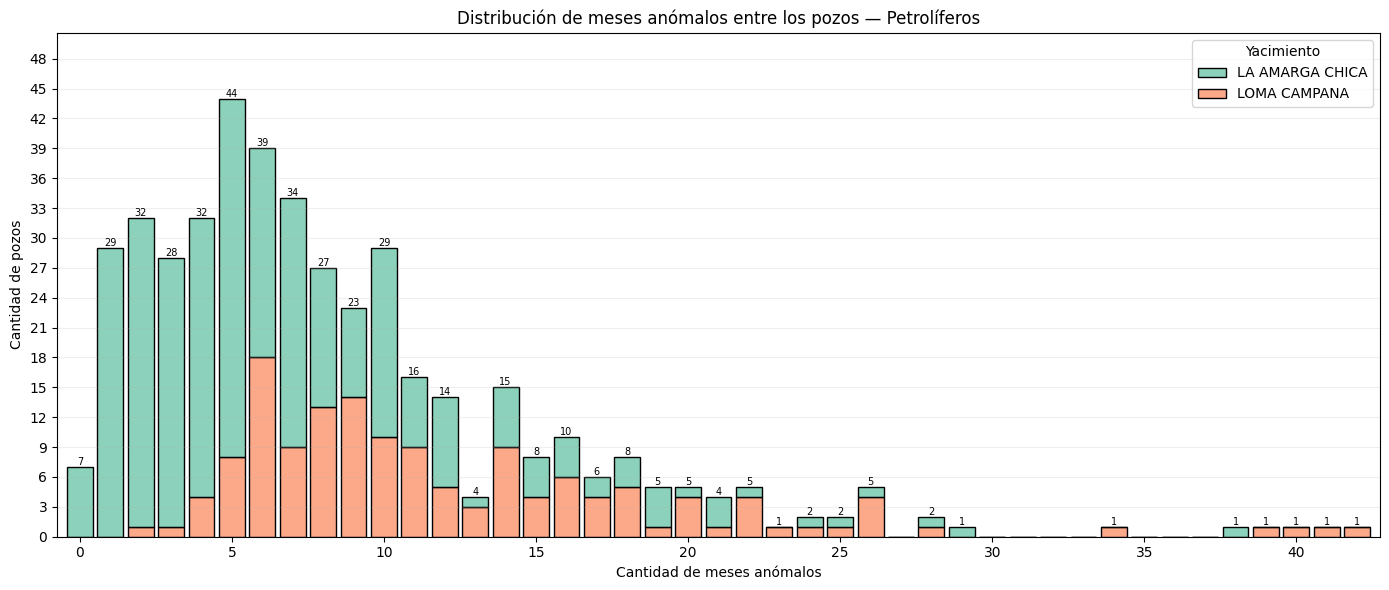

Pozos representados: 443
Pozos sin meses evaluables: 6


,cantidad_pozos
meses_anomalos,
0,7
1,29
2,32
3,28
4,32
5,44
6,39
7,34
8,27


In [28]:
pozos_con_anomalias = resumen_mensual.index[resumen_mensual.meses_anomalos > 0].tolist()
pozos_evaluados = resumen_mensual.loc[resumen_mensual.meses_evaluables > 0]
conteos = pozos_evaluados.meses_anomalos.astype(int)
distribucion = conteos.value_counts().reindex(range(int(conteos.max()) + 1), fill_value=0).sort_index()
distribucion.index.name = 'meses_anomalos'
distribucion.name = 'cantidad_pozos'
distribucion.to_csv(SALIDA/'distribucion_meses_anomalos.csv')
fig, ax = plt.subplots(figsize=(14, 6))
# Una fila por pozo: usar el último yacimiento observado, como en el mapa.
yacimiento_por_pozo = (df.sort_values('fecha').drop_duplicates('idpozo', keep='last')
                       .set_index('idpozo')['areayacimiento'])
datos_histograma = pozos_evaluados[['meses_anomalos']].copy()
datos_histograma['meses_anomalos'] = datos_histograma.meses_anomalos.astype(int)
datos_histograma['area_yacimiento'] = datos_histograma.index.map(yacimiento_por_pozo)
datos_histograma['area_yacimiento'] = datos_histograma.area_yacimiento.fillna('Sin dato')
orden_yacimientos = sorted(datos_histograma.area_yacimiento.unique())
sns.histplot(data=datos_histograma, x='meses_anomalos', hue='area_yacimiento',
             hue_order=orden_yacimientos, multiple='stack', discrete=True,
             stat='count', shrink=0.85, palette='Set2', ax=ax)
ax.get_legend().set_title('Yacimiento')
distribucion_yacimiento = pd.crosstab(datos_histograma.meses_anomalos,
                                    datos_histograma.area_yacimiento).reindex(distribucion.index, fill_value=0)
distribucion_yacimiento.to_csv(SALIDA/'distribucion_meses_anomalos_por_yacimiento.csv')
for cantidad_meses, cantidad_pozos in distribucion.items():
    if cantidad_pozos:
        ax.text(cantidad_meses, cantidad_pozos, str(cantidad_pozos), ha='center', va='bottom', fontsize=7)
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=25))
ax.set(xlabel='Cantidad de meses anómalos', ylabel='Cantidad de pozos',
       title='Distribución de meses anómalos entre los pozos — Petrolíferos', xlim=(-0.75, int(conteos.max()) + 0.75))
ax.set_ylim(0, max(1, distribucion.max()) * 1.15)
ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
print('Pozos representados:', int(distribucion.sum()))
print('Pozos sin meses evaluables:', int(resumen_mensual.meses_evaluables.eq(0).sum()))
display(distribucion[distribucion > 0].to_frame())

## 4.2. Boxplot de exploración inicial con coincidencias de Isolation Forest

Reproducimos la **celda 71** de `01_exploracion_inicial.ipynb`: solo “Extracción Efectiva”, una figura por fluido y tipo de pozo, agrupación por método de extracción, vista completa y vista ampliada de las cajas. Se conservan las tasas originales y las cercas de Tukey (`Q1 − 1,5×IQR`, `Q3 + 1,5×IQR`) calculadas dentro de cada método y tipo de pozo, sobre todo el historial.

- Gris: valores fuera de las cercas del boxplot.
- **Rojo: intersección entre outlier del boxplot y mes anómalo de Isolation Forest.**
- Naranja: outlier del boxplot sin evaluación mensual por calidad insuficiente.

Un mes puede ser anómalo multivariado y quedar dentro de una caja: no se colorea de rojo en este gráfico, porque pediste destacar anomalías **entre los outliers**. La tabla de coincidencias también cuenta esos casos. La vista ampliada puede ocultar puntos extremos por su escala; la vista completa los conserva. La coincidencia no mide exactitud: ninguno de los métodos es una etiqueta verdadera.

En esta versión, los boxplots utilizan únicamente los registros que quedan tras excluir meses de producción cero en los tres fluidos. Las cercas se recalculan sobre esa población filtrada.


,fluido,tipopozo,n_registros,outliers_boxplot,coincidencias,IF_dentro_caja,outlier_no_evaluado
0,prod_pet_dia,Petrolífero,23571,1044,458,3343,21
1,prod_gas_dia,Petrolífero,23571,1073,486,3315,21
2,prod_agua_dia,Petrolífero,23571,2660,1175,2626,300


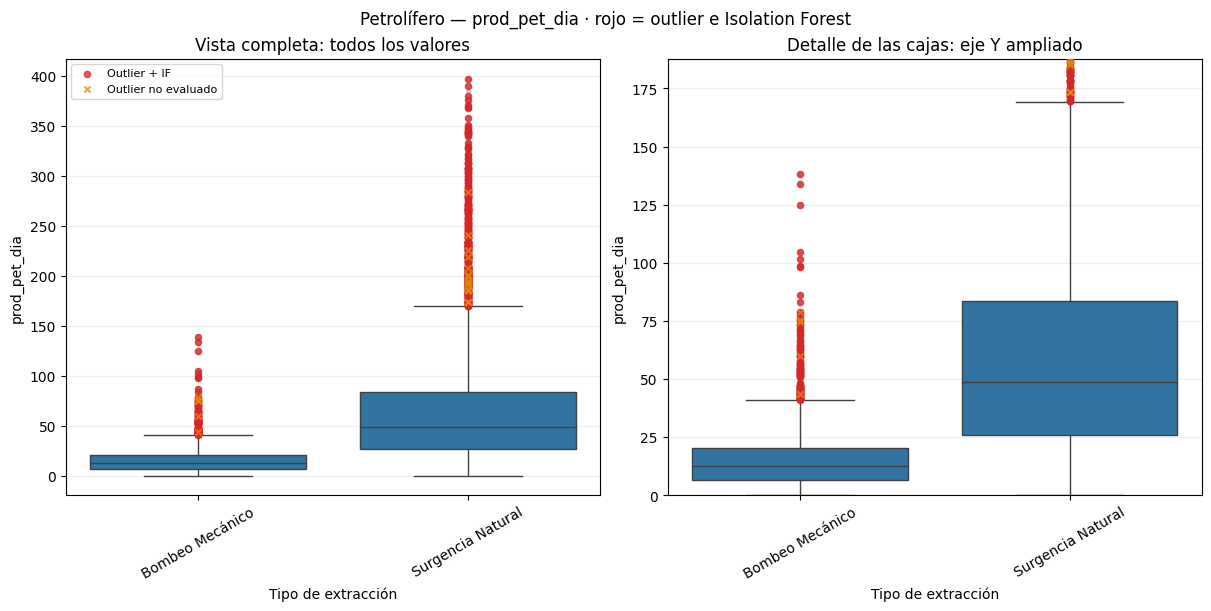

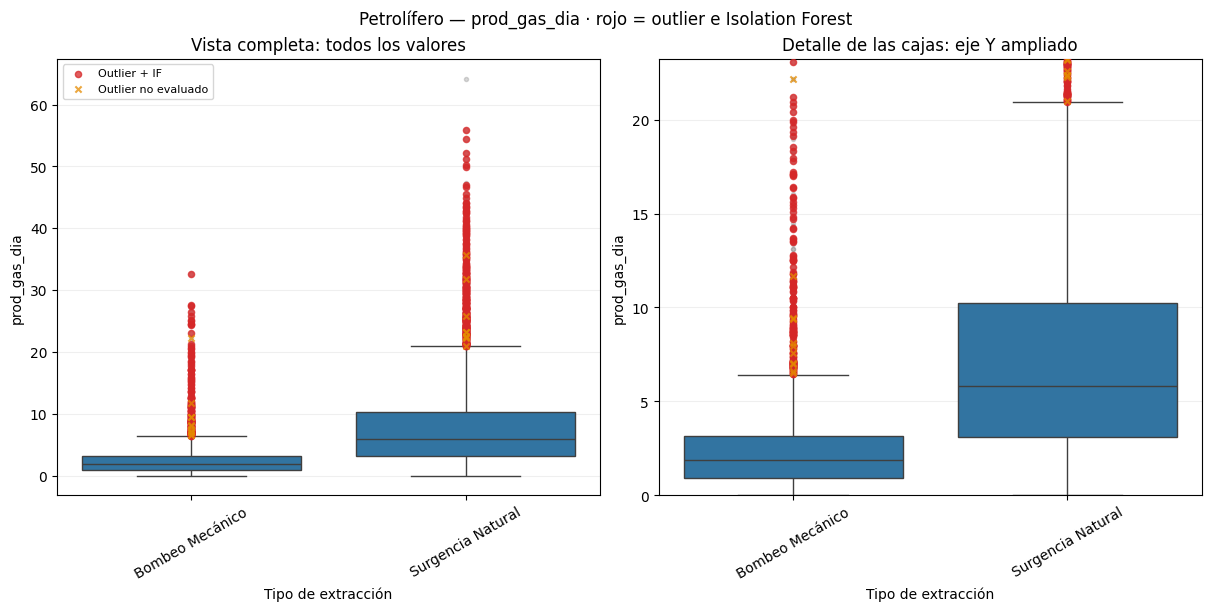

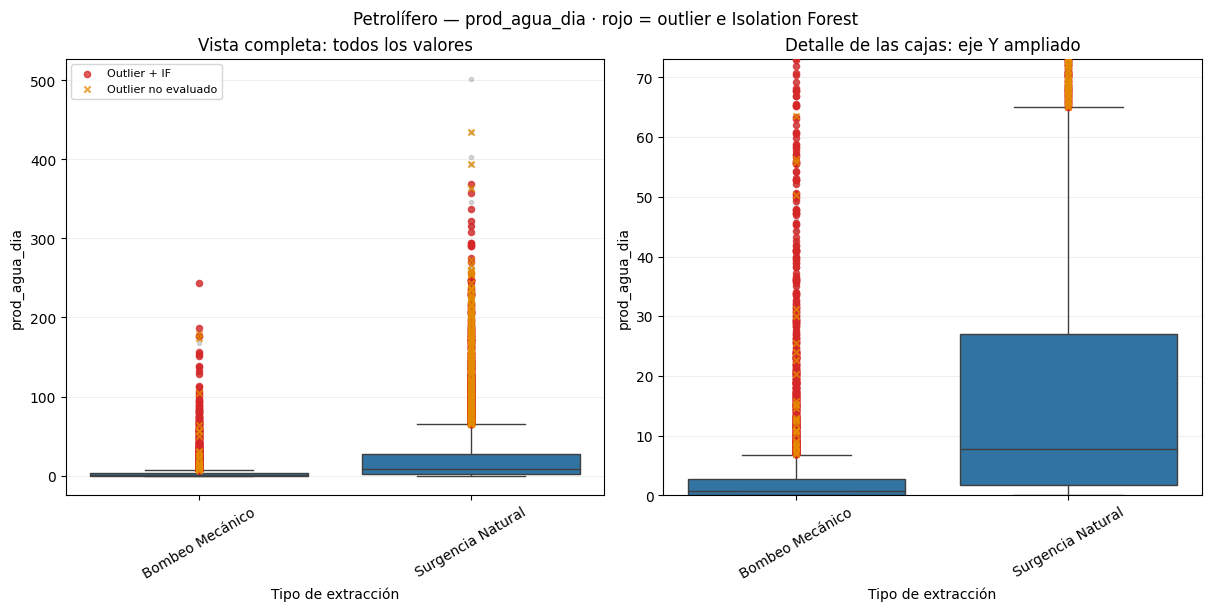

In [29]:
box = meses.loc[meses.tipoestado.eq('Extracción Efectiva')].copy()
coincidencias=[]
for col in FLUIDOS.values():
    for tipo,g in box.groupby('tipopozo'):
        g=g.dropna(subset=[col,'tipoextraccion']).copy()
        g=g.loc[np.isfinite(g[col])]
        if g.empty:continue
        orden=sorted(g.tipoextraccion.unique())
        grupos=g.groupby('tipoextraccion')[col]
        q1=grupos.transform('quantile',.25);q3=grupos.transform('quantile',.75);iqr=q3-q1
        g['outlier_boxplot']=(g[col]<q1-1.5*iqr)|(g[col]>q3+1.5*iqr)
        g['coincidencia']=g.outlier_boxplot & g.anomalo_mes.fillna(False)
        coincidencias.append(dict(fluido=col,tipopozo=tipo,n_registros=len(g),outliers_boxplot=int(g.outlier_boxplot.sum()),
            coincidencias=int(g.coincidencia.sum()),IF_dentro_caja=int((~g.outlier_boxplot & g.anomalo_mes.fillna(False)).sum()),
            outlier_no_evaluado=int((g.outlier_boxplot & g.anomalo_mes.isna()).sum())))
        g[['idpozo','fecha',col,'tipoextraccion','outlier_boxplot','anomalo_mes','coincidencia']].to_csv(SALIDA/f'boxplot_{col}_{tipo}.csv',index=False)
        fig,axes=plt.subplots(1,2,figsize=(12,6),constrained_layout=True)
        posicion={m:i for i,m in enumerate(orden)}
        for ax in axes:
            sns.boxplot(data=g,x='tipoextraccion',y=col,order=orden,showfliers=True,whis=1.5,
                flierprops={'marker':'o','markersize':3,'alpha':.3,'markerfacecolor':'gray','markeredgecolor':'gray'},ax=ax)
            for mask,color,label,marker in [(g.coincidencia,'#d62728','Outlier + IF','o'),
                (g.outlier_boxplot & g.anomalo_mes.isna(),'#e58b00','Outlier no evaluado','x')]:
                puntos=g.loc[mask]
                ax.scatter(puntos.tipoextraccion.map(posicion),puntos[col],c=color,s=20,marker=marker,label=label,zorder=5,alpha=.75)
            ax.set_xlabel('Tipo de extracción');ax.set_ylabel(col);ax.tick_params(axis='x',rotation=30);ax.grid(axis='y',alpha=.2)
        axes[0].set_title('Vista completa: todos los valores');axes[1].set_title('Detalle de las cajas: eje Y ampliado')
        cuartiles=g.groupby('tipoextraccion')[col].quantile([.25,.75]).unstack()
        inferior=(cuartiles[.25]-1.5*(cuartiles[.75]-cuartiles[.25])).min()
        superior=(cuartiles[.75]+1.5*(cuartiles[.75]-cuartiles[.25])).max()
        if superior>inferior:
            margen=(superior-inferior)*.08
            inferior=max(0,inferior-margen) if g[col].min()>=0 else inferior-margen
            axes[1].set_ylim(inferior,superior+margen)
        else:axes[1].text(.5,.9,'Los cuartiles coinciden: caja sin altura.',transform=axes[1].transAxes,ha='center')
        axes[0].legend(fontsize=8)
        fig.suptitle(f'{tipo} — {col} · rojo = outlier e Isolation Forest')
coincidencias=pd.DataFrame(coincidencias)
display(coincidencias)
coincidencias.to_csv(SALIDA/'coincidencias_boxplot_IF.csv',index=False)

## 5. Resultados petrolíferos, archivos y límites

**Qué ayuda a hacer:** priorizar pozos de primer año y meses de comportamiento inusual, localizar eventos, revisar cambios de extracción y comparar la detección multivariada con extremos de una variable.

**Qué no concluye:** causas operativas, errores confirmados, rentabilidad o producción futura. Un pozo productivo puede ser raro de forma legítima. `auto` puede marcar muchos casos, especialmente con poblaciones heterogéneas; no ajustamos el umbral para conseguir una cantidad deseada.

El análisis es retrospectivo. La columna de primer cambio usa todo el historial disponible y es descriptiva; sus valores posteriores al primer año no entran en el modelo anual. No se evalúa generalización futura. El primer año es el **primer año productivo observado en este dataset**; si comenzó antes de la cobertura, no conocemos su edad real.

El archivo ya fue filtrado en la exploración: no podemos recuperar anomalías eliminadas antes. Los meses de un pozo están correlacionados; no confundir número de filas con evidencia independiente. Para validar utilidad hace falta revisar candidatos con información operativa y también una muestra de no marcados.

**Archivos:** resultados por pozo y mes, cobertura, auditoría de edades, primer cambio de método, mapa HTML Esri, distribución de meses anómalos (PNG y CSV), boxplots y sus coincidencias. El ZIP contiene los resultados; en Colab se descarga desde Archivos o con la celda opcional del final.

Referencias: [Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html), [exploración inicial, celda 71](https://colab.research.google.com/drive/1PfdgTw-bKoxY5G8VxkPqxI9kWwWtLe7f), [modelos supervisados](https://colab.research.google.com/drive/1w9k50z4xAv9H-zSNdaL2tKyvk2MIJfHI).

In [30]:
resumen={
    'filas':len(df),'pozos':int(df.idpozo.nunique()),'ultimo_mes':str(df.fecha.max().date()),
    'pozos_primer_anio_evaluables':len(resultado_pozos),'pozos_primer_anio_anomalos':int(resultado_pozos.anomalo_pozo.sum()),
    'meses_evaluables':int(meses.evaluable_mes.sum()),'meses_anomalos':int(meses.anomalo_mes.sum()),
    'pozos_con_meses_anomalos':len(pozos_con_anomalias),
    'contamination':CONTAMINACION,'sklearn':sklearn.__version__,
    'features_pozos':FEATURES_POZOS,'features_meses':FEATURES_MESES}
print('Controles completados. Resumen de esta ejecución:')
display(pd.Series({k:v for k,v in resumen.items() if not isinstance(v,list)}).to_frame('valor'))
zip_resultados=shutil.make_archive(str(SALIDA),'zip',root_dir=SALIDA)
print('Archivo listo:',zip_resultados)
display(FileLink(zip_resultados))

Controles completados. Resumen de esta ejecución:


,valor
filas,23571
pozos,449
ultimo_mes,2026-09-01
pozos_primer_anio_evaluables,384
pozos_primer_anio_anomalos,53
meses_evaluables,22662
meses_anomalos,3801
pozos_con_meses_anomalos,436
contamination,auto
sklearn,1.6.1


Archivo listo: /content/resultados_isolation_forest_sin_ceros/petroliferos.zip


/content/resultados_isolation_forest_sin_ceros/petroliferos.zip

# 6. El Orejano: modelos exclusivos para pozos gasíferos

Repetimos el mismo procedimiento usando **solo El Orejano**, sin registros de La Amarga Chica ni Loma Campana. La separación se hace por yacimiento: se conservan 37 registros históricos etiquetados como petrolíferos del pozo 154188 ; los cambios de tipo ya se revisan en la celda 72 del exploratorio; no se altera su etiqueta ni se fragmenta su historial. Primero resumimos el primer año de cada pozo; después ajustamos un segundo Isolation Forest a sus registros mensuales.

Las variables terminadas en `_orejano` y la carpeta `gasiferos_el_orejano` mantienen estos modelos y resultados separados de los del bloque principal. El modelo anual tiene una población menor: interpretar las alertas como candidatos a revisión, no como fallas confirmadas. La separación no obliga a reducir el porcentaje marcado y los scores de modelos distintos no deben ordenarse como si fueran una única escala.


In [31]:
SALIDA_orejano = RAIZ_SALIDA / 'gasiferos_el_orejano'
SALIDA_orejano.mkdir(parents=True, exist_ok=True)
df_orejano = datos_preparados.loc[mask_orejano].copy().reset_index(drop=True)
# No eliminar registros históricos con otra etiqueta de tipo de pozo.
df_orejano.loc[~df_orejano.registro_valido].to_csv(SALIDA_orejano/'registros_no_evaluables.csv', index=False)
print('EL OREJANO:', df_orejano.idpozo.nunique(), 'pozos;', len(df_orejano), 'registros.')

EL OREJANO: 63 pozos; 4375 registros.


## 6.1. Edad y primer cambio de método en El Orejano

In [32]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
df_orejano['edad_pozo_meses_original'] = df_orejano.edad_pozo_meses
inicio_orejano = df_orejano.loc[df_orejano.tipoestado.eq('Extracción Efectiva')].groupby('idpozo').fecha.min()
df_orejano['fecha_inicio_observada'] = df_orejano.idpozo.map(inicio_orejano)
f0_orejano = df_orejano.fecha_inicio_observada
df_orejano['edad_pozo_meses'] = (df_orejano.fecha.dt.year - f0_orejano.dt.year) * 12 + df_orejano.fecha.dt.month - f0_orejano.dt.month
edad_distinta_orejano = df_orejano.edad_pozo_meses.notna() & df_orejano.edad_pozo_meses.ne(df_orejano.edad_pozo_meses_original)
print('Registros con edad corregida:', int(edad_distinta_orejano.sum()))
df_orejano.loc[edad_distinta_orejano, ['idpozo', 'fecha', 'tipoestado', 'edad_pozo_meses_original', 'edad_pozo_meses']].to_csv(SALIDA_orejano / 'auditoria_edad.csv', index=False)
metodos_orejano = df_orejano[['idpozo', 'fecha', 'edad_pozo_meses', 'tipoextraccion']].copy()
metodos_orejano['tipoextraccion'] = metodos_orejano.tipoextraccion.astype('string').str.strip().replace('', pd.NA)
metodos_orejano = metodos_orejano.dropna(subset=['tipoextraccion'])
metodos_orejano['metodo_anterior'] = metodos_orejano.groupby('idpozo').tipoextraccion.shift()
metodos_orejano['fecha_metodo_anterior'] = metodos_orejano.groupby('idpozo').fecha.shift()
metodos_orejano['cambio_metodo'] = metodos_orejano.metodo_anterior.notna() & metodos_orejano.tipoextraccion.ne(metodos_orejano.metodo_anterior)
cambios_orejano = metodos_orejano.loc[metodos_orejano.cambio_metodo].copy()
cambios_orejano['intervalo_cambio_meses'] = (cambios_orejano.fecha.dt.year - cambios_orejano.fecha_metodo_anterior.dt.year) * 12 + cambios_orejano.fecha.dt.month - cambios_orejano.fecha_metodo_anterior.dt.month
primer_cambio_orejano = cambios_orejano.drop_duplicates('idpozo').rename(columns={'edad_pozo_meses': 'edad_primer_cambio_metodo', 'fecha': 'fecha_primer_cambio_metodo', 'tipoextraccion': 'primer_metodo_nuevo'})
campos_cambio_orejano = ['idpozo', 'edad_primer_cambio_metodo', 'fecha_primer_cambio_metodo', 'fecha_metodo_anterior', 'intervalo_cambio_meses', 'metodo_anterior', 'primer_metodo_nuevo']
df_orejano = df_orejano.merge(primer_cambio_orejano[campos_cambio_orejano], on='idpozo', how='left', validate='many_to_one')
primer_cambio_orejano[campos_cambio_orejano].to_csv(SALIDA_orejano / 'primer_cambio_metodo.csv', index=False)
df_orejano['en_primer_anio'] = df_orejano.edad_pozo_meses.isin(PRIMER_ANIO)
display(df_orejano[['idpozo', 'edad_primer_cambio_metodo', 'intervalo_cambio_meses']].drop_duplicates().head(10))

# Excluir meses sin producción en los tres fluidos ANTES de crear perfiles y modelos.
# La edad y el primer cambio de método se calcularon con el historial completo.
sin_produccion_orejano = df_orejano[['prod_pet', 'prod_gas', 'prod_agua']].eq(0).all(axis=1)
meses_excluidos_cero_orejano = df_orejano.loc[sin_produccion_orejano].copy()
meses_excluidos_cero_orejano.to_csv(SALIDA_orejano/'meses_excluidos_produccion_cero.csv', index=False)
df_orejano = df_orejano.loc[~sin_produccion_orejano].copy().reset_index(drop=True)
print('Meses excluidos por producción cero en los tres fluidos:', len(meses_excluidos_cero_orejano))
print('Registros restantes antes de construir los modelos:', len(df_orejano))

Registros con edad corregida: 619


,idpozo,edad_primer_cambio_metodo,intervalo_cambio_meses
0,154187,NaN,NaN
105,154188,NaN,NaN
175,154744,NaN,NaN
231,154747,NaN,NaN
298,155525,NaN,NaN
361,155826,NaN,NaN
419,155827,NaN,NaN
478,155828,NaN,NaN
536,155829,NaN,NaN
594,156469,NaN,NaN


Meses excluidos por producción cero en los tres fluidos: 619
Registros restantes antes de construir los modelos: 3756


## 6.2. Perfiles del primer año: meses 0–11

Se aplica el mismo filtro de producción cero y el mismo requisito de doce meses 0–11 válidos. La edad no se reinicia al quitar filas.


In [33]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
ventana_orejano = df_orejano.loc[df_orejano.en_primer_anio].copy()
cobertura_orejano = df_orejano.groupby('idpozo').agg(edad_max=('edad_pozo_meses', 'max'))
cuentas_orejano = ventana_orejano.groupby('idpozo').agg(meses_presentes=('fecha', 'size'), meses_validos=('registro_valido', 'sum'), edades_distintas=('edad_pozo_meses', 'nunique'))
cobertura_orejano = cobertura_orejano.join(cuentas_orejano).fillna({'meses_presentes': 0, 'meses_validos': 0, 'edades_distintas': 0})
cobertura_orejano['evaluable_pozo'] = cobertura_orejano.meses_presentes.eq(12) & cobertura_orejano.meses_validos.eq(12) & cobertura_orejano.edades_distintas.eq(12)
cobertura_orejano['motivo'] = np.select([cobertura_orejano.evaluable_pozo, cobertura_orejano.edad_max.isna(), cobertura_orejano.edad_max.lt(11), cobertura_orejano.meses_presentes.lt(12)], ['evaluable', 'sin inicio productivo observado', 'primer año aún no completo', 'faltan meses del primer año'], default='registros inválidos en el primer año')
cobertura_orejano.to_csv(SALIDA_orejano / 'cobertura_primer_anio.csv')
elegibles_orejano = cobertura_orejano.index[cobertura_orejano.evaluable_pozo]
v_orejano = ventana_orejano.loc[ventana_orejano.idpozo.isin(elegibles_orejano)].copy()
DESCRIBIR_orejano = TASAS + ['fraccion_tiempo_operativo']
perfiles_orejano = v_orejano.groupby('idpozo')[DESCRIBIR_orejano].agg(['mean', 'median', 'std', 'min', 'max'])
perfiles_orejano.columns = ['__'.join(c_orejano) for c_orejano in perfiles_orejano.columns]
perfiles_orejano['fraccion_meses_tef_cero'] = v_orejano.groupby('idpozo').tef.apply(lambda s_orejano: float(s_orejano.eq(0).mean()))
cambios_12_orejano = cambios_orejano.loc[cambios_orejano.edad_pozo_meses.isin(PRIMER_ANIO)].groupby('idpozo').edad_pozo_meses.min()
perfiles_orejano['hubo_cambio_metodo_12m'] = perfiles_orejano.index.isin(cambios_12_orejano.index).astype(int)
perfiles_orejano['edad_cambio_metodo_12m'] = perfiles_orejano.index.map(cambios_12_orejano).fillna(12)
dummies_12_orejano = codificar_categorias(v_orejano)
proporciones_categoricas_orejano = dummies_12_orejano.groupby(v_orejano.idpozo).mean().add_prefix('proporcion_12m_')
perfiles_orejano = perfiles_orejano.join(proporciones_categoricas_orejano, validate='one_to_one')
FEATURES_POZOS_orejano = perfiles_orejano.columns.tolist()
print('Pozos evaluables:', len(perfiles_orejano), '| No evaluables:', int((~cobertura_orejano.evaluable_pozo).sum()))
display(cobertura_orejano.motivo.value_counts().to_frame('pozos'))
display(perfiles_orejano.head())

Pozos evaluables: 56 | No evaluables: 7


,pozos
motivo,
evaluable,56
faltan meses del primer año,7


,prod_pet_dia_modelo__mean,prod_pet_dia_modelo__median,prod_pet_dia_modelo__std,prod_pet_dia_modelo__min,prod_pet_dia_modelo__max,prod_gas_dia_modelo__mean,prod_gas_dia_modelo__median,prod_gas_dia_modelo__std,prod_gas_dia_modelo__min,prod_gas_dia_modelo__max,...,fraccion_tiempo_operativo__min,fraccion_tiempo_operativo__max,fraccion_meses_tef_cero,hubo_cambio_metodo_12m,edad_cambio_metodo_12m,proporcion_12m_tipoextraccion=Surgencia Natural,proporcion_12m_tipoestado=Extracción Efectiva,proporcion_12m_tipopozo=Gasífero,proporcion_12m_areayacimiento=EL OREJANO,proporcion_12m_clasificacion=EXPLOTACION
idpozo,,,,,,,,,,,,,,,,,,,,,
154187,0.002662,0.000000,0.007966,0.0,0.027652,54.545461,61.488099,26.440157,5.070000,85.391718,...,0.100000,0.997419,0.0,0,12.0,1.0,1.0,1.0,1.0,1.0
154188,0.025594,0.000000,0.063658,0.0,0.208912,81.669128,78.210788,47.066169,5.075000,151.673032,...,0.066667,0.999032,0.0,0,12.0,1.0,1.0,1.0,1.0,1.0
154744,0.484124,0.175191,0.630156,0.0,1.697207,54.916523,58.119150,32.178506,2.869919,113.642733,...,0.242258,0.998387,0.0,0,12.0,1.0,1.0,1.0,1.0,1.0
154747,1.788893,0.977888,2.020233,0.0,5.791946,53.261392,38.282495,46.699023,2.691800,128.194401,...,0.133226,1.000000,0.0,0,12.0,1.0,1.0,1.0,1.0,1.0
155829,0.020465,0.000000,0.052156,0.0,0.171747,18.359838,17.837574,9.610830,4.512325,30.072760,...,0.039355,1.000000,0.0,0,12.0,1.0,1.0,1.0,1.0,1.0


## 6.3. Isolation Forest de pozos gasíferos

Mismas variables e hiperparámetros; el ajuste se realiza exclusivamente con los datos de este grupo.

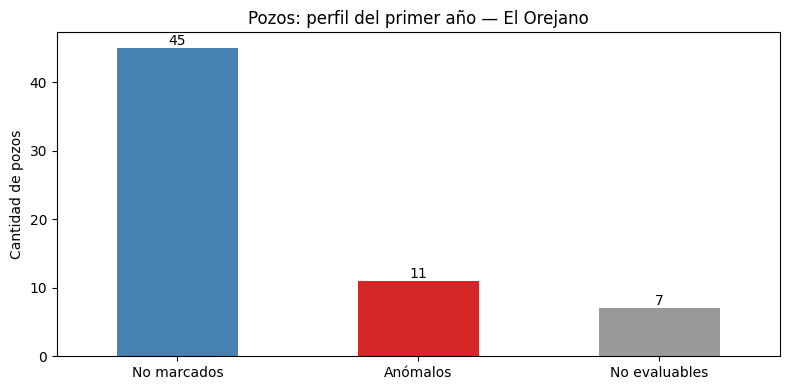

Umbral automático (score): 0.5


,score_pozo,anomalo_pozo,tipopozo,areayacimiento,edad_primer_cambio_metodo
idpozo,,,,,
165714,0.763610,True,Gasífero,EL OREJANO,NaN
160847,0.574347,True,Gasífero,EL OREJANO,NaN
156470,0.560622,True,Gasífero,EL OREJANO,NaN
155829,0.540293,True,Gasífero,EL OREJANO,NaN
154747,0.532741,True,Gasífero,EL OREJANO,NaN
156472,0.530266,True,Gasífero,EL OREJANO,NaN
156471,0.527305,True,Gasífero,EL OREJANO,NaN
159378,0.525848,True,Gasífero,EL OREJANO,NaN
158426,0.521504,True,Gasífero,EL OREJANO,NaN


anomalo_pozo,False,True
tipopozo,,
Gasífero,45,11


In [34]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
X_pozos_orejano = perfiles_orejano.copy()
cols_log_orejano = [c_orejano for c_orejano in FEATURES_POZOS_orejano if any((c_orejano.startswith(t_orejano + '__') for t_orejano in TASAS))]
X_pozos_orejano[cols_log_orejano] = np.log1p(X_pozos_orejano[cols_log_orejano])
modelo_pozos_orejano = IsolationForest(n_estimators=N_ARBOLES, contamination=CONTAMINACION, random_state=SEMILLA, n_jobs=-1)
modelo_pozos_orejano.fit(X_pozos_orejano)
resultado_pozos_orejano = perfiles_orejano.copy()
resultado_pozos_orejano['anomalo_pozo'] = modelo_pozos_orejano.predict(X_pozos_orejano) == -1
resultado_pozos_orejano['score_pozo'] = -modelo_pozos_orejano.score_samples(X_pozos_orejano)
meta_orejano = df_orejano.sort_values('fecha').drop_duplicates('idpozo', keep='last').set_index('idpozo')
meta_cols_orejano = ['areayacimiento', 'tipopozo', 'coordenadax', 'coordenaday', 'edad_primer_cambio_metodo', 'intervalo_cambio_meses']
resultado_pozos_orejano = resultado_pozos_orejano.join(meta_orejano[meta_cols_orejano]).sort_values('score_pozo', ascending=False)
resultado_pozos_orejano.to_csv(SALIDA_orejano / 'resultado_pozos.csv')
conteo_orejano = pd.Series({'No marcados': int((~resultado_pozos_orejano.anomalo_pozo).sum()), 'Anómalos': int(resultado_pozos_orejano.anomalo_pozo.sum()), 'No evaluables': int((~cobertura_orejano.evaluable_pozo).sum())})
ax_orejano = conteo_orejano.plot.bar(color=['#4682b4', '#d62728', '#999999'], figsize=(8, 4), rot=0)
for i_orejano, n_orejano in enumerate(conteo_orejano):
    ax_orejano.text(i_orejano, n_orejano, str(n_orejano), ha='center', va='bottom')
ax_orejano.set(title='Pozos: perfil del primer año — El Orejano', ylabel='Cantidad de pozos')
plt.tight_layout()
plt.show()
print('Umbral automático (score):', -modelo_pozos_orejano.offset_)
display(resultado_pozos_orejano[['score_pozo', 'anomalo_pozo', 'tipopozo', 'areayacimiento', 'edad_primer_cambio_metodo']].head(20))
display(pd.crosstab(resultado_pozos_orejano.tipopozo, resultado_pozos_orejano.anomalo_pozo))

## 6.4. Mapa Esri de El Orejano

Pozos sin ubicación válida: 0


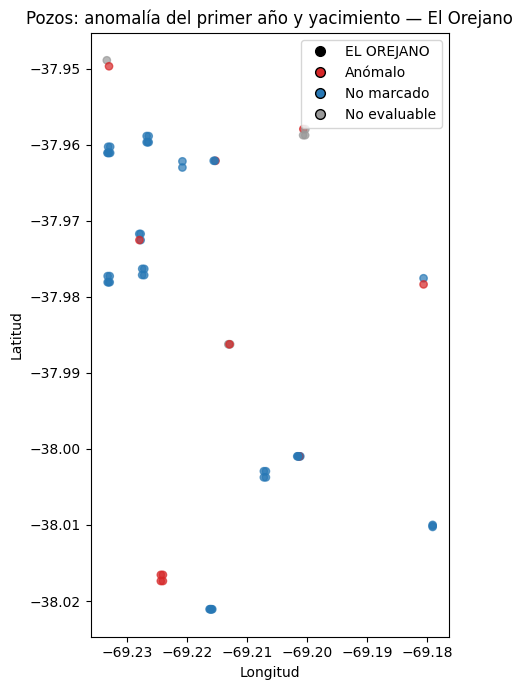

In [35]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
ubicaciones_orejano = df_orejano.dropna(subset=['coordenadax', 'coordenaday']).sort_values('fecha')
valid_geo_orejano = ubicaciones_orejano.coordenadax.between(-180, 180) & ubicaciones_orejano.coordenaday.between(-90, 90)
ubicaciones_orejano = ubicaciones_orejano.loc[valid_geo_orejano]
variaciones_orejano = ubicaciones_orejano[['idpozo', 'coordenadax', 'coordenaday']].drop_duplicates().groupby('idpozo').size()
variaciones_orejano.loc[variaciones_orejano > 1].to_csv(SALIDA_orejano / 'pozos_con_varias_ubicaciones.csv', header=['ubicaciones'])
mapa_df_orejano = meta_orejano[['areayacimiento']].join(ubicaciones_orejano.drop_duplicates('idpozo', keep='last').set_index('idpozo')[['coordenadax', 'coordenaday']])
mapa_df_orejano = mapa_df_orejano.join(resultado_pozos_orejano[['anomalo_pozo', 'score_pozo']])
mapa_df_orejano['estado_modelo'] = np.select([mapa_df_orejano.anomalo_pozo.isna(), mapa_df_orejano.anomalo_pozo.eq(True)], ['No evaluable', 'Anómalo'], default='No marcado')
print('Pozos sin ubicación válida:', int(mapa_df_orejano[['coordenadax', 'coordenaday']].isna().any(axis=1).sum()))
mapa_df_orejano = mapa_df_orejano.dropna(subset=['coordenadax', 'coordenaday']).copy()
areas_orejano = sorted(mapa_df_orejano.areayacimiento.dropna().unique())
FORMAS_orejano = dict(zip(areas_orejano, ['o', '^', 's', 'D', 'v', 'P', 'X']))
COLORES_orejano = {'Anómalo': '#d62728', 'No marcado': '#2878b5', 'No evaluable': '#999999'}
fig_orejano, ax_orejano = plt.subplots(figsize=(10, 7))
for area_orejano, g_orejano in mapa_df_orejano.groupby('areayacimiento'):
    ax_orejano.scatter(g_orejano.coordenadax, g_orejano.coordenaday, c=g_orejano.estado_modelo.map(COLORES_orejano), marker=FORMAS_orejano.get(area_orejano, 'o'), s=28, alpha=0.7)
leyenda_orejano = [Line2D([0], [0], marker=FORMAS_orejano.get(a_orejano, 'o'), color='none', markerfacecolor='black', label=a_orejano, markersize=7) for a_orejano in areas_orejano]
leyenda_orejano += [Line2D([0], [0], marker='o', color='none', markerfacecolor=c_orejano, label=e_orejano, markersize=7) for e_orejano, c_orejano in COLORES_orejano.items()]
ax_orejano.legend(handles=leyenda_orejano, bbox_to_anchor=(1, 1))
ax_orejano.set(xlabel='Longitud', ylabel='Latitud', title='Pozos: anomalía del primer año y yacimiento — El Orejano')
ax_orejano.set_aspect(1 / np.cos(np.deg2rad(mapa_df_orejano.coordenaday.mean())))
plt.tight_layout()
plt.show()
mapa_orejano = folium.Map(location=[mapa_df_orejano.coordenaday.mean(), mapa_df_orejano.coordenadax.mean()], zoom_start=10, tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}', attr='Esri')
css_formas_orejano = {}
for i_orejano, area_orejano in enumerate(areas_orejano):
    css_formas_orejano[area_orejano] = ['border-radius:50%;', 'clip-path:polygon(50% 0,0 100%,100% 100%);', ''][i_orejano % 3]
    capa_orejano = folium.FeatureGroup(name=area_orejano, show=True)
    for pozo_orejano, r_orejano in mapa_df_orejano.loc[mapa_df_orejano.areayacimiento.eq(area_orejano)].iterrows():
        color_orejano = COLORES_orejano[r_orejano.estado_modelo]
        icono_orejano = folium.DivIcon(html=f'<div style="width:12px;height:12px;background:{color_orejano};border:1px solid white;{css_formas_orejano[area_orejano]}"></div>', icon_size=(12, 12), icon_anchor=(6, 6))
        folium.Marker([r_orejano.coordenaday, r_orejano.coordenadax], icon=icono_orejano, popup=f'Pozo {pozo_orejano}<br>{html.escape(str(area_orejano))}<br>{r_orejano.estado_modelo}<br>Score: {r_orejano.score_pozo:.3f}').add_to(capa_orejano)
    capa_orejano.add_to(mapa_orejano)
leyenda_html_orejano = '<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;padding:12px;border:1px solid #777;color:black"><b>Color: primer año</b><br>'
for estado_orejano, color_orejano in COLORES_orejano.items():
    leyenda_html_orejano += f'<span style="color:{color_orejano}">●</span> {estado_orejano}<br>'
leyenda_html_orejano += '<b>Forma: yacimiento</b><br>'
for area_orejano in areas_orejano:
    leyenda_html_orejano += f'<span style="display:inline-block;width:12px;height:12px;background:black;{css_formas_orejano[area_orejano]}"></span> {html.escape(str(area_orejano))}<br>'
mapa_orejano.get_root().html.add_child(folium.Element(leyenda_html_orejano + '</div>'))
folium.LayerControl().add_to(mapa_orejano)
display(mapa_orejano)

## 6.5. Isolation Forest de meses de El Orejano

Mismas variables e hiperparámetros; el ajuste se realiza exclusivamente con los datos de este grupo.

Los meses sin producción conjunta se eliminan antes de crear las variables mensuales. La comparación sigue exigiendo el **mes calendario anterior**: el mes posterior a uno eliminado queda sin contexto y no se evalúa; no se conectan meses separados por un hueco.


,registros
motivo_no_evaluable_mes,
evaluable,3594
falta mes calendario anterior válido,99
sin mes de vida anterior disponible,63


Meses evaluables: 3594 | Meses anómalos: 394
Pozos con algún mes anómalo: 62
Meses anómalos con aumento de al menos un fluido: 318


,idpozo,fecha,edad_pozo_meses,score_mes,aumento_anomalo,reactivacion_en_mes_anomalo
3655,160847,2019-08-01,1,0.709939,True,True
3742,165714,2025-02-01,4,0.676848,True,False
2771,158423,2026-06-01,105,0.660748,True,True
3739,165714,2024-11-01,1,0.646995,False,False
986,156966,2018-05-01,21,0.643039,True,True
1931,157970,2017-05-01,1,0.640554,True,False
2883,158426,2024-09-01,84,0.632861,True,True
697,156741,2016-07-01,1,0.629245,True,True
1128,157106,2016-10-01,1,0.625302,True,False
3494,159835,2019-09-01,11,0.624989,True,True


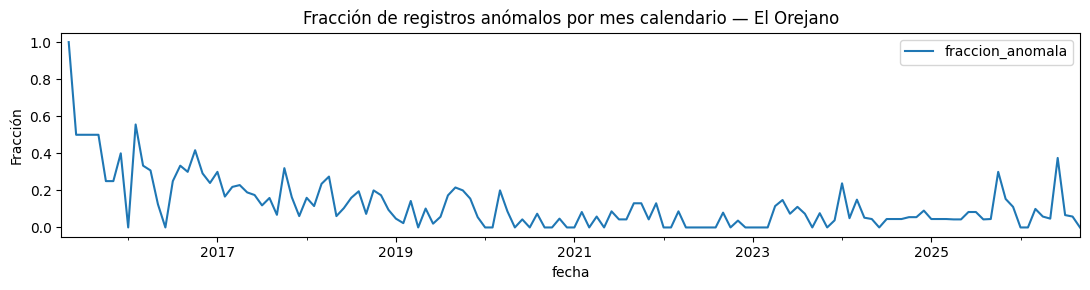

In [36]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
prev_orejano = df_orejano[['idpozo', 'fecha', 'registro_valido'] + TASAS].copy()
prev_orejano['fecha'] += pd.DateOffset(months=1)
prev_orejano = prev_orejano.rename(columns={c_orejano: c_orejano + '_previo' for c_orejano in ['registro_valido'] + TASAS})
meses_orejano = df_orejano.merge(prev_orejano, on=['idpozo', 'fecha'], how='left', validate='one_to_one')
meses_orejano['sin_mes_previo'] = ~meses_orejano.registro_valido_previo.eq(True)
meses_orejano['evaluable_mes'] = meses_orejano.registro_valido & meses_orejano.edad_pozo_meses.ge(1) & ~meses_orejano.sin_mes_previo
meses_orejano['motivo_no_evaluable_mes'] = np.select([~meses_orejano.registro_valido, meses_orejano.edad_pozo_meses.isna() | meses_orejano.edad_pozo_meses.lt(1), meses_orejano.sin_mes_previo], ['datos de producción/tef inválidos', 'sin mes de vida anterior disponible', 'falta mes calendario anterior válido'], default='evaluable')
FEATURES_MESES_orejano = []
X_meses_orejano = pd.DataFrame(index=meses_orejano.index)
for c_orejano in TASAS:
    X_meses_orejano[c_orejano + '_log'] = np.log1p(meses_orejano[c_orejano])
    cambio_orejano = np.log1p(meses_orejano[c_orejano]) - np.log1p(meses_orejano[c_orejano + '_previo'])
    X_meses_orejano[c_orejano + '_cambio_log'] = cambio_orejano.mask(meses_orejano.sin_mes_previo, 0)
    meses_orejano[c_orejano + '_aumenta'] = ~meses_orejano.sin_mes_previo & meses_orejano[c_orejano].gt(meses_orejano[c_orejano + '_previo'])
    meses_orejano[c_orejano + '_reactiva'] = ~meses_orejano.sin_mes_previo & meses_orejano[c_orejano + '_previo'].eq(0) & meses_orejano[c_orejano].gt(0)
X_meses_orejano['fraccion_tiempo_operativo'] = meses_orejano.fraccion_tiempo_operativo
X_meses_orejano['edad_pozo_meses_log'] = np.log1p(meses_orejano.edad_pozo_meses.clip(lower=0))
dummies_meses_orejano = codificar_categorias(meses_orejano)
X_meses_orejano = X_meses_orejano.join(dummies_meses_orejano, validate='one_to_one')
FEATURES_MESES_orejano = X_meses_orejano.columns.tolist()
validos_orejano = meses_orejano.evaluable_mes
modelo_meses_orejano = IsolationForest(n_estimators=N_ARBOLES, contamination=CONTAMINACION, random_state=SEMILLA, n_jobs=-1)
modelo_meses_orejano.fit(X_meses_orejano.loc[validos_orejano])
meses_orejano['anomalo_mes'] = pd.Series(pd.NA, index=meses_orejano.index, dtype='boolean')
meses_orejano.loc[validos_orejano, 'anomalo_mes'] = modelo_meses_orejano.predict(X_meses_orejano.loc[validos_orejano]) == -1
meses_orejano['score_mes'] = np.nan
meses_orejano.loc[validos_orejano, 'score_mes'] = -modelo_meses_orejano.score_samples(X_meses_orejano.loc[validos_orejano])
meses_orejano['aumento_anomalo'] = meses_orejano.anomalo_mes.fillna(False) & meses_orejano[[c_orejano + '_aumenta' for c_orejano in TASAS]].any(axis=1)
meses_orejano['reactivacion_en_mes_anomalo'] = meses_orejano.anomalo_mes.fillna(False) & meses_orejano[[c_orejano + '_reactiva' for c_orejano in TASAS]].any(axis=1)
meses_orejano.to_csv(SALIDA_orejano / 'resultado_meses.csv', index=False)
display(meses_orejano.motivo_no_evaluable_mes.value_counts().to_frame('registros'))
resumen_mensual_orejano = meses_orejano.groupby('idpozo').agg(meses_observados=('fecha', 'size'), meses_evaluables=('evaluable_mes', 'sum'), meses_anomalos=('anomalo_mes', 'sum'), aumentos_anomalos=('aumento_anomalo', 'sum'))
resumen_mensual_orejano['fraccion_meses_anomalos'] = resumen_mensual_orejano.meses_anomalos / resumen_mensual_orejano.meses_evaluables.replace(0, np.nan)
resumen_mensual_orejano.to_csv(SALIDA_orejano / 'resumen_mensual_por_pozo.csv')
print('Meses evaluables:', int(validos_orejano.sum()), '| Meses anómalos:', int(meses_orejano.anomalo_mes.sum()))
print('Pozos con algún mes anómalo:', int((resumen_mensual_orejano.meses_anomalos > 0).sum()))
print('Meses anómalos con aumento de al menos un fluido:', int(meses_orejano.aumento_anomalo.sum()))
display(meses_orejano.loc[meses_orejano.anomalo_mes.fillna(False), ['idpozo', 'fecha', 'edad_pozo_meses', 'score_mes', 'aumento_anomalo', 'reactivacion_en_mes_anomalo']].sort_values('score_mes', ascending=False).head(20))
por_fecha_orejano = meses_orejano.groupby('fecha').agg(evaluables=('evaluable_mes', 'sum'), anomalos=('anomalo_mes', 'sum'))
por_fecha_orejano['fraccion_anomala'] = por_fecha_orejano.anomalos / por_fecha_orejano.evaluables.replace(0, np.nan)
por_fecha_orejano[['fraccion_anomala']].plot(figsize=(11, 3), title='Fracción de registros anómalos por mes calendario — El Orejano', ylabel='Fracción')
plt.tight_layout()
plt.show()

## 6.6. Historial interactivo de pozos de El Orejano

In [37]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt

def graficar_historial_dummies_orejano(idpozo_orejano, datos_meses_orejano=meses_orejano, datos_cambios_orejano=cambios_orejano):
    g_orejano = datos_meses_orejano.loc[datos_meses_orejano.idpozo.eq(idpozo_orejano)].sort_values('fecha')
    if g_orejano.empty:
        raise ValueError('idpozo no encontrado')
    continuo_orejano = g_orejano.set_index('fecha').reindex(pd.date_range(g_orejano.fecha.min(), g_orejano.fecha.max(), freq='MS'))
    fechas_alerta_orejano = g_orejano.loc[g_orejano.anomalo_mes.fillna(False), 'fecha']
    fechas_cambio_orejano = datos_cambios_orejano.loc[datos_cambios_orejano.idpozo.eq(idpozo_orejano), 'fecha']
    fig_orejano, axes_orejano = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
    for ax_orejano, (nombre_orejano, original_orejano), c_orejano in zip(axes_orejano, FLUIDOS.items(), TASAS):
        ax_orejano.plot(continuo_orejano.index, continuo_orejano[c_orejano], marker='.', label='Tasa observada válida')
        for j_orejano, f_orejano in enumerate(fechas_alerta_orejano):
            ax_orejano.axvline(f_orejano, color='#d62728', alpha=0.35, linestyle='--', label='Mes anómalo' if j_orejano == 0 else None)
        for j_orejano, f_orejano in enumerate(fechas_cambio_orejano):
            ax_orejano.axvline(f_orejano, color='#e58b00', alpha=0.7, linestyle=':', label='Cambio de extracción' if j_orejano == 0 else None)
        f0_orejano = g_orejano.fecha_inicio_observada.iloc[0]
        if pd.notna(f0_orejano):
            ax_orejano.axvspan(f0_orejano, f0_orejano + pd.DateOffset(months=12), alpha=0.08, color='blue', label='Primer año observado')
        ax_orejano.set_ylabel(nombre_orejano + '\n' + UNIDADES[nombre_orejano])
        ax_orejano.grid(alpha=0.2)
    axes_orejano[0].legend(loc='upper right')
    axes_orejano[-1].set_xlabel('Mes calendario')
    fig_orejano.suptitle(f'Pozo {idpozo_orejano} · {len(fechas_alerta_orejano)} meses anómalos (Modelo Mensual)')
    plt.tight_layout()
    return fig_orejano

def actualizar_historial_dummies_orejano(idpozo_seleccion_orejano):
    fig_orejano = graficar_historial_dummies_orejano(idpozo_seleccion_orejano)
    plt.show()
pozos_disponibles_orejano = sorted(df_orejano.idpozo.unique())
interact(actualizar_historial_dummies_orejano, idpozo_seleccion_orejano=widgets.Dropdown(options=pozos_disponibles_orejano, value=pozos_disponibles_orejano[0], description='ID Pozo (Dummies):', disabled=False))

interactive(children=(Dropdown(description='ID Pozo (Dummies):', options=(np.int64(154187), np.int64(154188), …

<function __main__.actualizar_historial_dummies_orejano(idpozo_seleccion_orejano)>

## 6.7. Distribución de meses anómalos de El Orejano

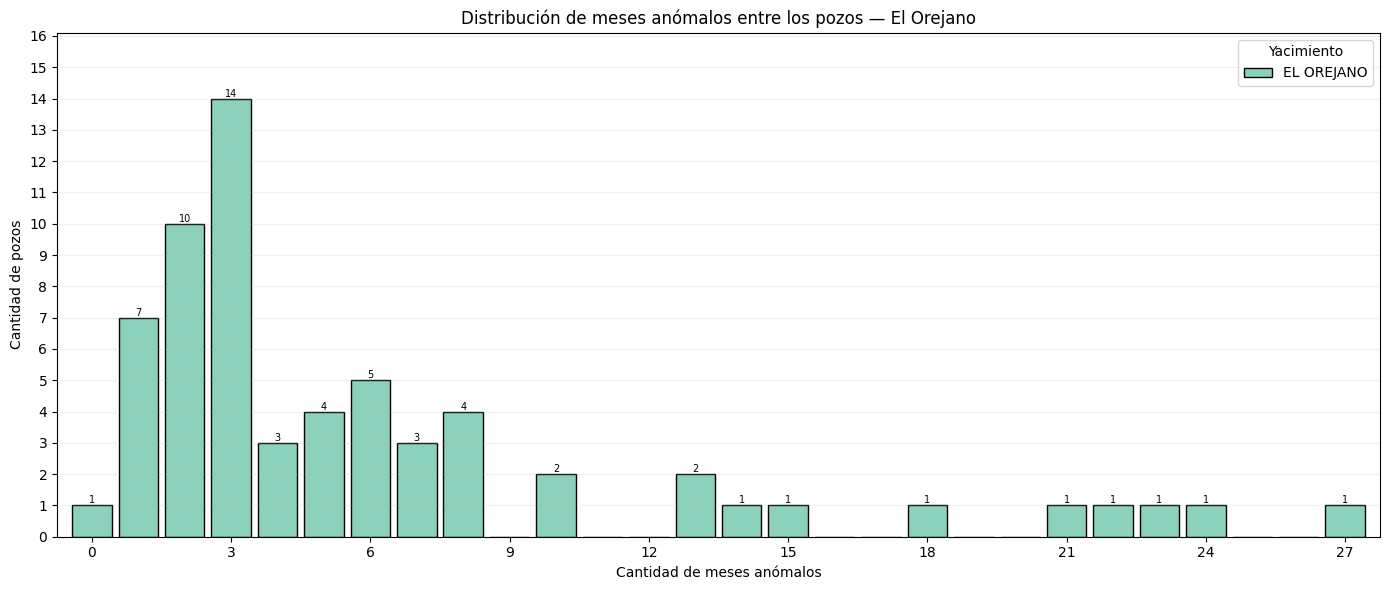

Pozos representados: 63
Pozos sin meses evaluables: 0


,cantidad_pozos
meses_anomalos,
0,1
1,7
2,10
3,14
4,3
5,4
6,5
7,3
8,4


In [38]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
pozos_con_anomalias_orejano = resumen_mensual_orejano.index[resumen_mensual_orejano.meses_anomalos > 0].tolist()
pozos_evaluados_orejano = resumen_mensual_orejano.loc[resumen_mensual_orejano.meses_evaluables > 0]
conteos_orejano = pozos_evaluados_orejano.meses_anomalos.astype(int)
distribucion_orejano = conteos_orejano.value_counts().reindex(range(int(conteos_orejano.max()) + 1), fill_value=0).sort_index()
distribucion_orejano.index.name = 'meses_anomalos'
distribucion_orejano.name = 'cantidad_pozos'
distribucion_orejano.to_csv(SALIDA_orejano / 'distribucion_meses_anomalos.csv')
fig_orejano, ax_orejano = plt.subplots(figsize=(14, 6))
yacimiento_por_pozo_orejano = df_orejano.sort_values('fecha').drop_duplicates('idpozo', keep='last').set_index('idpozo')['areayacimiento']
datos_histograma_orejano = pozos_evaluados_orejano[['meses_anomalos']].copy()
datos_histograma_orejano['meses_anomalos'] = datos_histograma_orejano.meses_anomalos.astype(int)
datos_histograma_orejano['area_yacimiento'] = datos_histograma_orejano.index.map(yacimiento_por_pozo_orejano)
datos_histograma_orejano['area_yacimiento'] = datos_histograma_orejano.area_yacimiento.fillna('Sin dato')
orden_yacimientos_orejano = sorted(datos_histograma_orejano.area_yacimiento.unique())
sns.histplot(data=datos_histograma_orejano, x='meses_anomalos', hue='area_yacimiento', hue_order=orden_yacimientos_orejano, multiple='stack', discrete=True, stat='count', shrink=0.85, palette='Set2', ax=ax_orejano)
ax_orejano.get_legend().set_title('Yacimiento')
distribucion_yacimiento_orejano = pd.crosstab(datos_histograma_orejano.meses_anomalos, datos_histograma_orejano.area_yacimiento).reindex(distribucion_orejano.index, fill_value=0)
distribucion_yacimiento_orejano.to_csv(SALIDA_orejano / 'distribucion_meses_anomalos_por_yacimiento.csv')
for cantidad_meses_orejano, cantidad_pozos_orejano in distribucion_orejano.items():
    if cantidad_pozos_orejano:
        ax_orejano.text(cantidad_meses_orejano, cantidad_pozos_orejano, str(cantidad_pozos_orejano), ha='center', va='bottom', fontsize=7)
from matplotlib.ticker import MaxNLocator
ax_orejano.xaxis.set_major_locator(MaxNLocator(integer=True))
ax_orejano.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=25))
ax_orejano.set(xlabel='Cantidad de meses anómalos', ylabel='Cantidad de pozos', title='Distribución de meses anómalos entre los pozos — El Orejano', xlim=(-0.75, int(conteos_orejano.max()) + 0.75))
ax_orejano.set_ylim(0, max(1, distribucion_orejano.max()) * 1.15)
ax_orejano.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()
print('Pozos representados:', int(distribucion_orejano.sum()))
print('Pozos sin meses evaluables:', int(resumen_mensual_orejano.meses_evaluables.eq(0).sum()))
display(distribucion_orejano[distribucion_orejano > 0].to_frame())

## 6.8. Boxplots de El Orejano

En esta versión, los boxplots utilizan únicamente los registros que quedan tras excluir meses de producción cero en los tres fluidos. Las cercas se recalculan sobre esa población filtrada.


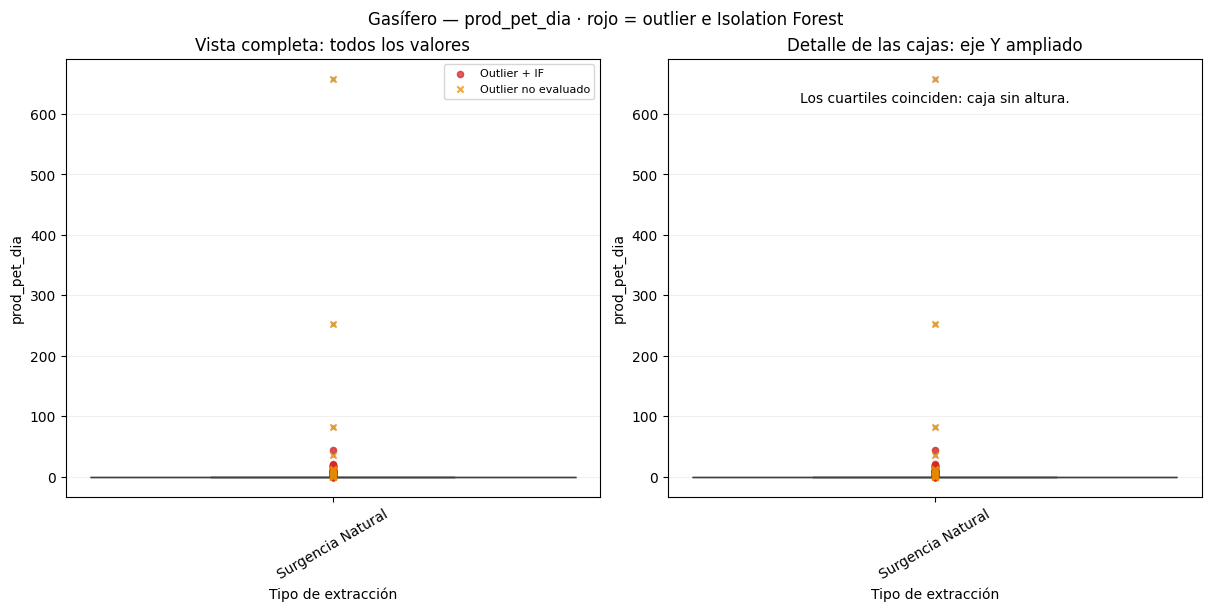

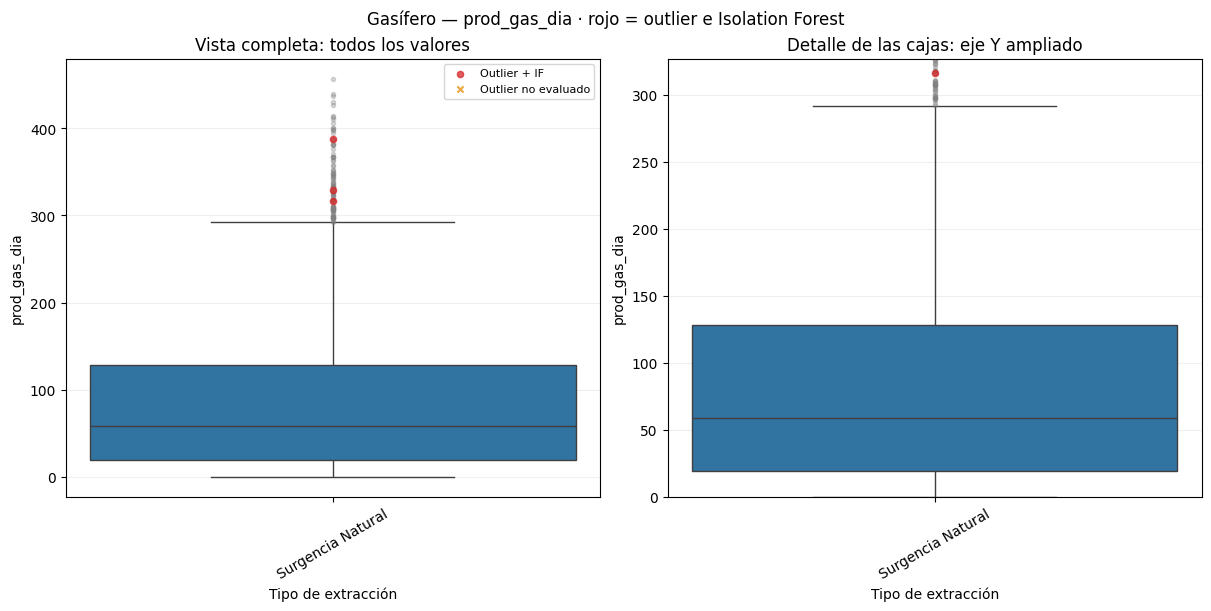

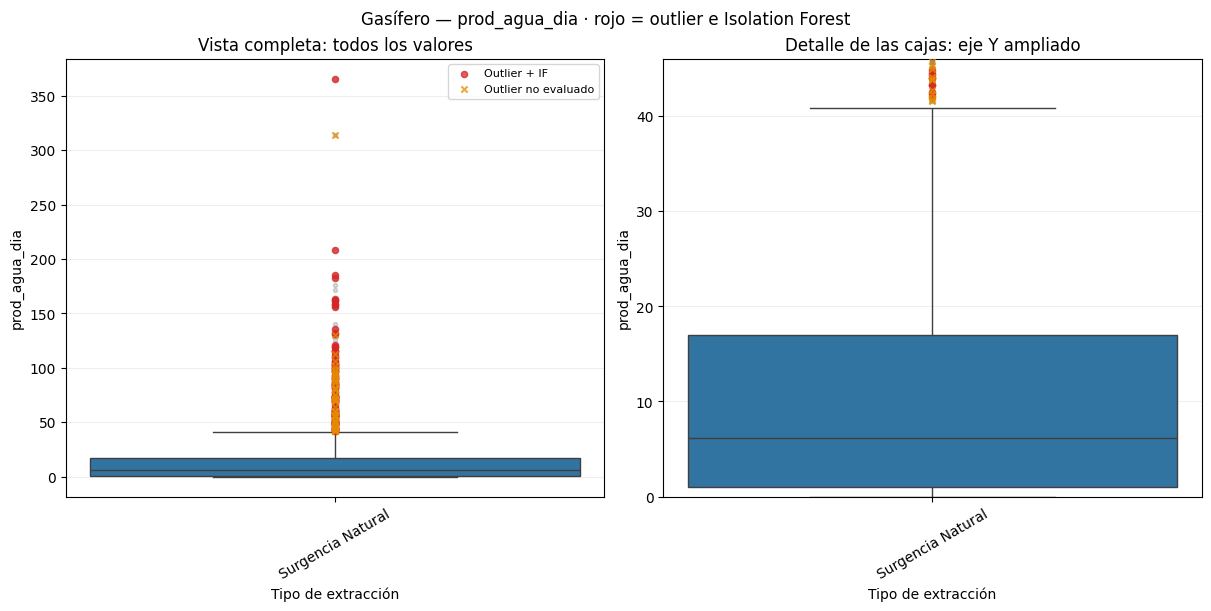

,fluido,tipopozo,n_registros,outliers_boxplot,coincidencias,IF_dentro_caja,outlier_no_evaluado
0,prod_pet_dia,Gasífero,3756,545,227,167,21
1,prod_gas_dia,Gasífero,3756,94,3,391,0
2,prod_agua_dia,Gasífero,3756,363,122,272,55


In [39]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
box_orejano = meses_orejano.loc[meses_orejano.tipoestado.eq('Extracción Efectiva')].copy()
coincidencias_orejano = []
for col_orejano in FLUIDOS.values():
    for tipo_orejano, g_orejano in box_orejano.groupby('tipopozo'):
        g_orejano = g_orejano.dropna(subset=[col_orejano, 'tipoextraccion']).copy()
        g_orejano = g_orejano.loc[np.isfinite(g_orejano[col_orejano])]
        if g_orejano.empty:
            continue
        orden_orejano = sorted(g_orejano.tipoextraccion.unique())
        grupos_orejano = g_orejano.groupby('tipoextraccion')[col_orejano]
        q1_orejano = grupos_orejano.transform('quantile', 0.25)
        q3_orejano = grupos_orejano.transform('quantile', 0.75)
        iqr_orejano = q3_orejano - q1_orejano
        g_orejano['outlier_boxplot'] = (g_orejano[col_orejano] < q1_orejano - 1.5 * iqr_orejano) | (g_orejano[col_orejano] > q3_orejano + 1.5 * iqr_orejano)
        g_orejano['coincidencia'] = g_orejano.outlier_boxplot & g_orejano.anomalo_mes.fillna(False)
        coincidencias_orejano.append(dict(fluido=col_orejano, tipopozo=tipo_orejano, n_registros=len(g_orejano), outliers_boxplot=int(g_orejano.outlier_boxplot.sum()), coincidencias=int(g_orejano.coincidencia.sum()), IF_dentro_caja=int((~g_orejano.outlier_boxplot & g_orejano.anomalo_mes.fillna(False)).sum()), outlier_no_evaluado=int((g_orejano.outlier_boxplot & g_orejano.anomalo_mes.isna()).sum())))
        g_orejano[['idpozo', 'fecha', col_orejano, 'tipoextraccion', 'outlier_boxplot', 'anomalo_mes', 'coincidencia']].to_csv(SALIDA_orejano / f'boxplot_{col_orejano}_{tipo_orejano}.csv', index=False)
        fig_orejano, axes_orejano = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
        posicion_orejano = {m_orejano: i_orejano for i_orejano, m_orejano in enumerate(orden_orejano)}
        for ax_orejano in axes_orejano:
            sns.boxplot(data=g_orejano, x='tipoextraccion', y=col_orejano, order=orden_orejano, showfliers=True, whis=1.5, flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.3, 'markerfacecolor': 'gray', 'markeredgecolor': 'gray'}, ax=ax_orejano)
            for mask_orejano, color_orejano, label_orejano, marker_orejano in [(g_orejano.coincidencia, '#d62728', 'Outlier + IF', 'o'), (g_orejano.outlier_boxplot & g_orejano.anomalo_mes.isna(), '#e58b00', 'Outlier no evaluado', 'x')]:
                puntos_orejano = g_orejano.loc[mask_orejano]
                ax_orejano.scatter(puntos_orejano.tipoextraccion.map(posicion_orejano), puntos_orejano[col_orejano], c=color_orejano, s=20, marker=marker_orejano, label=label_orejano, zorder=5, alpha=0.75)
            ax_orejano.set_xlabel('Tipo de extracción')
            ax_orejano.set_ylabel(col_orejano)
            ax_orejano.tick_params(axis='x', rotation=30)
            ax_orejano.grid(axis='y', alpha=0.2)
        axes_orejano[0].set_title('Vista completa: todos los valores')
        axes_orejano[1].set_title('Detalle de las cajas: eje Y ampliado')
        cuartiles_orejano = g_orejano.groupby('tipoextraccion')[col_orejano].quantile([0.25, 0.75]).unstack()
        inferior_orejano = (cuartiles_orejano[0.25] - 1.5 * (cuartiles_orejano[0.75] - cuartiles_orejano[0.25])).min()
        superior_orejano = (cuartiles_orejano[0.75] + 1.5 * (cuartiles_orejano[0.75] - cuartiles_orejano[0.25])).max()
        if superior_orejano > inferior_orejano:
            margen_orejano = (superior_orejano - inferior_orejano) * 0.08
            inferior_orejano = max(0, inferior_orejano - margen_orejano) if g_orejano[col_orejano].min() >= 0 else inferior_orejano - margen_orejano
            axes_orejano[1].set_ylim(inferior_orejano, superior_orejano + margen_orejano)
        else:
            axes_orejano[1].text(0.5, 0.9, 'Los cuartiles coinciden: caja sin altura.', transform=axes_orejano[1].transAxes, ha='center')
        axes_orejano[0].legend(fontsize=8)
        fig_orejano.suptitle(f'{tipo_orejano} — {col_orejano} · rojo = outlier e Isolation Forest')
        plt.show()
coincidencias_orejano = pd.DataFrame(coincidencias_orejano)
display(coincidencias_orejano)
coincidencias_orejano.to_csv(SALIDA_orejano / 'coincidencias_boxplot_IF.csv', index=False)

## 6.9. Controles y archivos de El Orejano

In [40]:
# Mismo procedimiento, aplicado únicamente a El Orejano.
resumen_orejano = {'filas': len(df_orejano), 'pozos': int(df_orejano.idpozo.nunique()), 'ultimo_mes': str(df_orejano.fecha.max().date()), 'pozos_primer_anio_evaluables': len(resultado_pozos_orejano), 'pozos_primer_anio_anomalos': int(resultado_pozos_orejano.anomalo_pozo.sum()), 'meses_evaluables': int(meses_orejano.evaluable_mes.sum()), 'meses_anomalos': int(meses_orejano.anomalo_mes.sum()), 'pozos_con_meses_anomalos': len(pozos_con_anomalias_orejano), 'edades_corregidas': int(edad_distinta_orejano.sum()), 'contamination': CONTAMINACION, 'sklearn': sklearn.__version__, 'features_pozos': FEATURES_POZOS_orejano, 'features_meses': FEATURES_MESES_orejano}
print('Controles completados. Resumen de esta ejecución:')
display(pd.Series({k_orejano: v_orejano for k_orejano, v_orejano in resumen_orejano.items() if not isinstance(v_orejano, list)}).to_frame('valor'))
zip_resultados_orejano = shutil.make_archive(str(SALIDA_orejano), 'zip', root_dir=SALIDA_orejano)
print('Archivo listo:', zip_resultados_orejano)
display(FileLink(zip_resultados_orejano))

Controles completados. Resumen de esta ejecución:


,valor
filas,3756
pozos,63
ultimo_mes,2026-09-01
pozos_primer_anio_evaluables,56
pozos_primer_anio_anomalos,11
meses_evaluables,3594
meses_anomalos,394
pozos_con_meses_anomalos,62
edades_corregidas,619
contamination,auto


Archivo listo: /content/resultados_isolation_forest_sin_ceros/gasiferos_el_orejano.zip


/content/resultados_isolation_forest_sin_ceros/gasiferos_el_orejano.zip

## 7. Resumen de los cuatro modelos y descarga conjunta

Cada porcentaje utiliza como denominador los casos evaluables de su propio grupo. No es una medida de exactitud. Se comprueba que ambos grupos cubran la base y que no compartan pozos. El ZIP conserva carpetas separadas para petrolíferos y El Orejano.


In [41]:
comparacion = pd.DataFrame([
    {'grupo':'Petrolíferos', 'unidad':'Pozo (primer año)', 'evaluables':len(resultado_pozos), 'anomalos':int(resultado_pozos.anomalo_pozo.sum())},
    {'grupo':'El Orejano — gasíferos', 'unidad':'Pozo (primer año)', 'evaluables':len(resultado_pozos_orejano), 'anomalos':int(resultado_pozos_orejano.anomalo_pozo.sum())},
    {'grupo':'Petrolíferos', 'unidad':'Pozo-mes', 'evaluables':int(meses.evaluable_mes.sum()), 'anomalos':int(meses.anomalo_mes.sum())},
    {'grupo':'El Orejano — gasíferos', 'unidad':'Pozo-mes', 'evaluables':int(meses_orejano.evaluable_mes.sum()), 'anomalos':int(meses_orejano.anomalo_mes.sum())}
])
comparacion['porcentaje_anomalo'] = 100 * comparacion.anomalos / comparacion.evaluables
comparacion.to_csv(RAIZ_SALIDA/'resumen_cuatro_modelos.csv', index=False)
display(comparacion)
zip_resultados = shutil.make_archive(str(RAIZ_SALIDA), 'zip', root_dir=RAIZ_SALIDA)
print('Verificado: ningún pozo compartido entre grupos. Archivo conjunto:', zip_resultados)
display(FileLink(zip_resultados))

,grupo,unidad,evaluables,anomalos,porcentaje_anomalo
0,Petrolíferos,Pozo (primer año),384,53,13.802083
1,El Orejano — gasíferos,Pozo (primer año),56,11,19.642857
2,Petrolíferos,Pozo-mes,22662,3801,16.772571
3,El Orejano — gasíferos,Pozo-mes,3594,394,10.962716


Verificado: ningún pozo compartido entre grupos. Archivo conjunto: /content/resultados_isolation_forest_sin_ceros.zip


/content/resultados_isolation_forest_sin_ceros.zip

### Descarga opcional en Colab
Ejecutá la siguiente celda si querés descargar el ZIP al equipo. No es necesario para entrenar ni visualizar resultados.

In [42]:
DESCARGAR_ZIP = False
if DESCARGAR_ZIP:
    from google.colab import files
    files.download(zip_resultados)